# Apollo Hospitals - Appointment No-Show and Patient Engagement Analysis
Goal: understand why patients miss appointments and how to reduce it.

<hr style="border:3px solid #1f77b4">

# PART 1: SETUPSETUP

## 1. Import Libraries

In [1]:
import pandas as pd                 
import numpy as np                  
import matplotlib.pyplot as plt
import seaborn as sns            
import warnings

warnings.filterwarnings("ignore")    # hides non-critical warning messages

## 2. Display and Chart Settings

In [2]:
# Show all columns and use a clean chart style
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

<hr style="border:3px solid #2ca02c">

# PART 2: LOAD THE DATA

## 3. Load Both Files

In [3]:
df = pd.read_csv("Datasets/apollo_appointments_fact.csv", keep_default_na=False, na_values=[""])   # appointments
doctors = pd.read_csv("Datasets/apollo_doctors_dim.csv", keep_default_na=False, na_values=[""])    # doctors

print("Data loaded successfully")

Data loaded successfully


## 4. Check the Size of the Data

In [4]:
print("Appointments table:", df.shape)   
print("Doctors table     :", doctors.shape)   

Appointments table: (75000, 52)
Doctors table     : (320, 15)


## 5. Preview Appointments Table

In [5]:
df.head()

,appointment_id,patient_id,doctor_id,appointment_date,appointment_day,appointment_day_of_week,appointment_month,appointment_quarter,appointment_year,appointment_hour,appointment_minute,time_slot,time_of_day,booking_date,booking_lead_days,booking_channel,appointment_type,specialty,city,state,hospital_name,patient_age,age_group,patient_gender,patient_city_tier,patient_chronic_condition,apollo_member,membership_type,reminder_type,reminders_sent,patient_prior_visits,patient_prior_no_shows,is_first_visit,repeat_visit,visit_reason,appointment_status,no_show,no_show_flag,cancellation_reason,consultation_fee,discount_pct,actual_fee_charged,insurance_coverage,insurance_provider,insurance_covered_amount,patient_out_of_pocket,revenue_realized,payment_mode,wait_time_minutes,consultation_duration_min,patient_satisfaction_score,doctor_utilization_pct
0,APPT5000001,PAT117608,DOC1035,2023-11-15,Wednesday,2,11,Q4,2023,15,30,15:30,Afternoon,2023-11-14,1,Apollo App,In-Clinic,Cardiology,Bengaluru,Karnataka,Apollo Clinic Jayanagar,76,Senior (60+),Female,1,None,No,None,SMS + WhatsApp,2,1,0,0,Yes,Joint Pain,Completed,No,0,None,2700,0,2700,No,None,0,2700,2700,UPI,11.0,40.0,4.8,84.2
1,APPT5000002,PAT128732,DOC1049,2023-03-13,Monday,0,3,Q1,2023,9,0,09:00,Morning,2023-03-05,8,Website,In-Clinic,Paediatrics,Pune,Maharashtra,Apollo Spectra Pune,6,Child (0-12),Male,1,None,No,None,SMS Only,1,1,0,0,Yes,Fever & Infection,Completed,No,0,None,1400,0,1400,No,None,0,1400,1400,UPI,21.0,18.0,4.1,64.5
2,APPT5000003,PAT137532,DOC1033,2022-02-07,Monday,0,2,Q1,2022,17,0,17:00,Evening,2022-02-07,0,Walk-In,In-Clinic,General Physician,Bengaluru,Karnataka,Apollo Spectra Koramangala,69,Senior (60+),Male,1,Hypothyroidism,No,None,SMS + WhatsApp + Call,3,1,0,0,Yes,Routine Checkup,Completed,No,0,None,600,0,600,No,None,0,600,600,Net Banking,6.0,6.0,5.0,75.6
3,APPT5000004,PAT113284,DOC1288,2023-11-20,Monday,0,11,Q4,2023,17,15,17:15,Evening,2023-11-20,0,Walk-In,In-Clinic,Dermatology,Delhi,Delhi,Apollo Hospital Sarita Vihar,47,Middle-aged (46-60),Female,1,Hypertension,No,None,SMS + WhatsApp + Call,3,1,0,0,Yes,Eye Care,Completed,No,0,None,1275,0,1275,No,None,0,1275,1275,UPI,2.0,25.0,4.4,68.6
4,APPT5000005,PAT107443,DOC1064,2024-02-02,Friday,4,2,Q1,2024,19,30,19:30,Evening,2024-02-01,1,Apollo App,In-Clinic,Gastroenterology,Coimbatore,Tamil Nadu,Apollo Clinic Coimbatore,45,Adult (31-45),Female,2,Hypertension,Yes,Apollo Silver,SMS + WhatsApp,2,1,0,0,Yes,Respiratory Issue,Completed,No,0,None,2000,15,1700,No,None,0,1700,1700,Cash,7.0,13.0,3.5,67.7


## 6. Preview Doctors Table

In [6]:
doctors.head()

,doctor_id,doctor_name,specialty,qualification,experience_years,city,state,hospital_name,consultation_fee,rating,total_reviews,available_days,avg_slot_duration_min,accepts_insurance,teleconsult_enabled
0,DOC1001,Dr. Deepa Sharma,Urology,"MBBS, MCh",12,Bengaluru,Karnataka,Apollo Hospital Bannerghatta,2300,4.4,1502,Mon-Fri,15,Yes,No
1,DOC1002,Dr. Venkatesan Khan,Paediatrics,"MBBS, MS, FRCS",25,Chandigarh,Punjab,Apollo Clinic Sector 8,1200,4.5,2453,Mon-Sat,10,Yes,Yes
2,DOC1003,Dr. Pradeep Menon,General Physician,"MBBS, DM",13,Mumbai,Maharashtra,Apollo Clinic Andheri,700,4.7,995,Mon-Wed-Fri-Sat,15,No,No
3,DOC1004,Dr. Vivek Mathew,General Physician,"MBBS, MD",31,Mumbai,Maharashtra,Apollo Hospital Navi Mumbai,1000,4.9,666,Mon-Wed-Fri-Sat,20,Yes,Yes
4,DOC1005,Dr. Savita Philip,General Physician,"MBBS, MD, PhD",5,Mumbai,Maharashtra,Apollo Hospital Navi Mumbai,600,4.5,1383,Mon-Sat,30,Yes,Yes


## 7. Column Types

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75000 entries, 0 to 74999
Data columns (total 52 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   appointment_id              75000 non-null  object 
 1   patient_id                  75000 non-null  object 
 2   doctor_id                   75000 non-null  object 
 3   appointment_date            75000 non-null  object 
 4   appointment_day             75000 non-null  object 
 5   appointment_day_of_week     75000 non-null  int64  
 6   appointment_month           75000 non-null  int64  
 7   appointment_quarter         75000 non-null  object 
 8   appointment_year            75000 non-null  int64  
 9   appointment_hour            75000 non-null  int64  
 10  appointment_minute          75000 non-null  int64  
 11  time_slot                   75000 non-null  object 
 12  time_of_day                 75000 non-null  object 
 13  booking_date                750

## 8. Missing Values

In [8]:
# Columns that have missing values, and how many
missing = df.isna().sum()
missing[missing > 0]

wait_time_minutes             19725
consultation_duration_min     19725
patient_satisfaction_score    19725
doctor_utilization_pct        19725
dtype: int64

<hr style="border:3px solid #ff7f0e">

# PART 3: DATA CLEANING

## 9. Check Duplicates

In [9]:
# Check for repeated appointment IDs 
duplicates = df["appointment_id"].duplicated().sum()
print("Duplicate appointment IDs:", duplicates)

Duplicate appointment IDs: 0


## 10. Appointment Status Counts

In [10]:
print("Number of appointments by status:")
print(df["appointment_status"].value_counts())
print()
print("Percentage of appointments by status:")
print(df["appointment_status"].value_counts(normalize=True) * 100)

Number of appointments by status:
appointment_status
Completed    55275
No-Show      11584
Cancelled     5793
Scheduled     2348
Name: count, dtype: int64

Percentage of appointments by status:
appointment_status
Completed    73.700000
No-Show      15.445333
Cancelled     7.724000
Scheduled     3.130667
Name: proportion, dtype: float64


## 11. Check How no_show_flag Is Stored

In [11]:
# IMPORTANT: Scheduled rows hold 0 here, so they must be excluded from the no-show rate
print("Status vs no_show (text label):")
print(pd.crosstab(df["appointment_status"], df["no_show"]))
print()
print("Status vs no_show_flag (number):")
print(pd.crosstab(df["appointment_status"], df["no_show_flag"]))

Status vs no_show (text label):
no_show              N/A     No    Yes
appointment_status                    
Cancelled              0   5793      0
Completed              0  55275      0
No-Show                0      0  11584
Scheduled           2348      0      0

Status vs no_show_flag (number):
no_show_flag            0      1
appointment_status              
Cancelled            5793      0
Completed           55275      0
No-Show                 0  11584
Scheduled            2348      0


Cancelled and Scheduled rows both hold 0 in `no_show_flag`, so Scheduled rows must be removed before calculating any no-show rate.

## 12. Convert Dates

In [12]:
df["appointment_date"] = pd.to_datetime(df["appointment_date"])
df["booking_date"] = pd.to_datetime(df["booking_date"])

print("Earliest appointment date:", df["appointment_date"].min().date())
print("Latest appointment date  :", df["appointment_date"].max().date())

Earliest appointment date: 2022-01-01
Latest appointment date  : 2024-12-31


## 13. Sanity Checks

In [13]:
print("Minimum lead days:", df["booking_lead_days"].min())
print("Maximum lead days:", df["booking_lead_days"].max())
print("Minimum age      :", df["patient_age"].min())
print("Maximum age      :", df["patient_age"].max())
print("Booked after appointment date:", (df["booking_date"] > df["appointment_date"]).sum())

Minimum lead days: 0
Maximum lead days: 30
Minimum age      : 1
Maximum age      : 85
Booked after appointment date: 0


## 14. Check Category Names

In [14]:
# Exact spellings, needed for filters later (e.g. Paediatrics)
print("Specialties:", df["specialty"].unique())
print()
print("Cities:", df["city"].unique())
print()
print("Age groups:", df["age_group"].unique())
print()
print("Reminder types:", df["reminder_type"].unique())

Specialties: ['Cardiology' 'Paediatrics' 'General Physician' 'Dermatology'
 'Gastroenterology' 'Orthopaedics' 'Psychiatry' 'Pulmonology' 'Neurology'
 'Ophthalmology' 'Gynaecology' 'Endocrinology' 'ENT' 'Urology']

Cities: ['Bengaluru' 'Pune' 'Delhi' 'Coimbatore' 'Kolkata' 'Mumbai' 'Chennai'
 'Indore' 'Kochi' 'Hyderabad' 'Ahmedabad' 'Lucknow' 'Bhopal' 'Chandigarh'
 'Jaipur']

Age groups: ['Senior (60+)' 'Child (0-12)' 'Middle-aged (46-60)' 'Adult (31-45)'
 'Teen (13-18)' 'Young Adult (19-30)']

Reminder types: ['SMS + WhatsApp' 'SMS Only' 'SMS + WhatsApp + Call' 'No Reminder']


<hr style="border:3px solid #9467bd">

# PART 4: NEW COLUMNS AND DATASETS

## 15. Create Weekend Column

In [15]:
# Monday = 0 ... Saturday = 5, Sunday = 6
df["is_weekend"] = df["appointment_day_of_week"].isin([5, 6])

print("Weekend appointments:", df["is_weekend"].sum())
print("Weekday appointments:", (~df["is_weekend"]).sum())

Weekend appointments: 21633
Weekday appointments: 53367


## 16. Create Lead Time Groups

In [16]:
# 0 days = same day (walk-ins), max is 30 days
df["lead_bucket"] = pd.cut(df["booking_lead_days"],
                           bins=[-1, 0, 3, 7, 14, 30],
                           labels=["Same day", "1-3", "4-7", "8-14", "15-30"])

print("Appointments in each lead time group:")
print(df["lead_bucket"].value_counts().sort_index())

Appointments in each lead time group:
lead_bucket
Same day    20810
1-3         26302
4-7         16442
8-14         9030
15-30        2416
Name: count, dtype: int64


## 17. Create Two Working Datasets
- `df_rate`: Completed + No-Show + Cancelled (no-show analysis)
- `df_comp`: Completed only (revenue and quality analysis)

In [17]:
# df_rate has NO Scheduled rows | df_comp has Completed rows only
df_rate = df[df["appointment_status"] != "Scheduled"]
df_comp = df[df["appointment_status"] == "Completed"]

print("Rows in df_rate:", len(df_rate))
print("Rows in df_comp:", len(df_comp))

Rows in df_rate: 72652
Rows in df_comp: 55275


## 18. Overall No-Show Rate

In [18]:
# No-show rate = no-shows / (Completed + No-Show + Cancelled)
rate = df_rate["no_show_flag"].mean() * 100
print("Overall no-show rate:", round(rate, 2), "%")

# Cross-check using counts
no_shows = (df_rate["appointment_status"] == "No-Show").sum()
print("Cross-check          :", round(no_shows / len(df_rate) * 100, 2), "%")

Overall no-show rate: 15.94 %
Cross-check          : 15.94 %


## 19. Example: No-Show Rate by Appointment Type

In [19]:
# This same pattern is reused for specialty, city, channel and more
result = df_rate.groupby("appointment_type")["no_show_flag"].mean() * 100
print("No-show rate (%) by appointment type:")
print(result.round(2))

No-show rate (%) by appointment type:
appointment_type
Home Visit       26.25
In-Clinic        12.18
Video Consult    21.06
Name: no_show_flag, dtype: float64


<hr style="border:3px solid #d62728">

# PART 5: BUSINESS OVERVIEW

<div style="border-left:6px solid #d62728; padding:8px 14px;">
<b>Q1.</b> How is appointment volume trending across months and quarters from 2022 to 2024?
</div>

## 20. Monthly Appointment Volume

In [20]:
# Rows = month (1-12), columns = year
monthly = df.groupby(["appointment_month", "appointment_year"]).size().unstack()

print("Appointments by month and year:")
print(monthly)

Appointments by month and year:
appointment_year   2022  2023  2024
appointment_month                  
1                  2426  2371  2427
2                  2012  2013  2078
3                  2085  2103  2033
4                  1926  1964  2024
5                  2033  2002  2013
6                  1823  1896  1862
7                  1833  1884  1862
8                  1835  1785  1832
9                  2115  2038  2083
10                 2206  2278  2291
11                 2299  2329  2225
12                 2275  2391  2348


## 21. Monthly Trend Chart

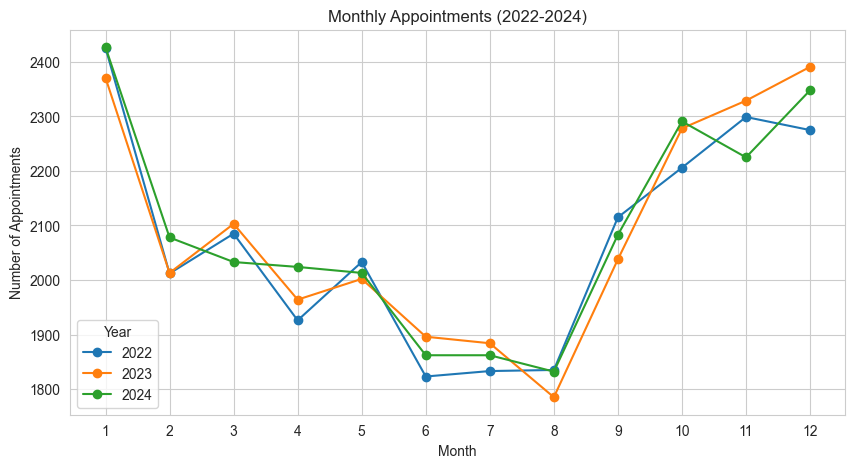

In [21]:
monthly.plot(marker="o", figsize=(10, 5), color=["#1f77b4", "#ff7f0e", "#2ca02c"])
plt.title("Monthly Appointments (2022-2024)")
plt.xlabel("Month")
plt.ylabel("Number of Appointments")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.show()

## 22. Quarterly Appointment Volume

Appointments by quarter and year:
appointment_year     2022  2023  2024
appointment_quarter                  
Q1                   6523  6487  6538
Q2                   5782  5862  5899
Q3                   5783  5707  5777
Q4                   6780  6998  6864


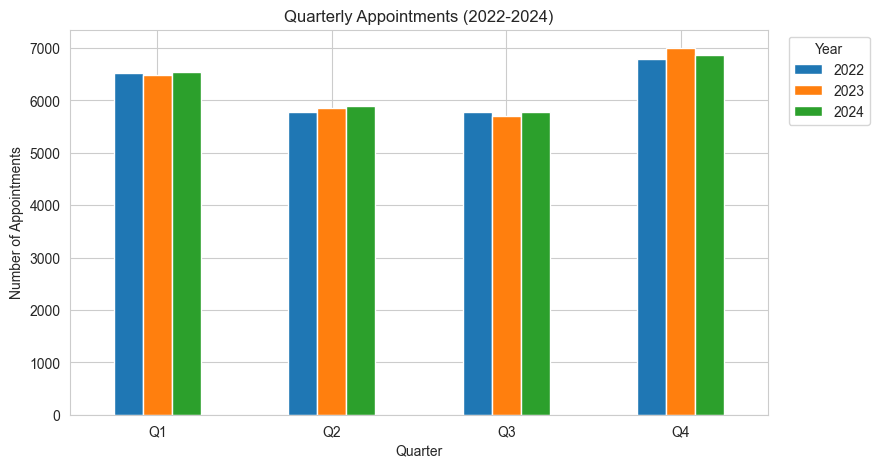

In [22]:
quarterly = df.groupby(["appointment_quarter", "appointment_year"]).size().unstack()

print("Appointments by quarter and year:")
print(quarterly)

quarterly.plot(kind="bar", figsize=(9, 5), color=["#1f77b4", "#ff7f0e", "#2ca02c"])
plt.title("Quarterly Appointments (2022-2024)")
plt.xlabel("Quarter")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=0)
plt.legend(title="Year", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

## 23. Yearly Total and Growth

In [23]:
yearly = df["appointment_year"].value_counts().sort_index()

print("Total appointments per year:")
print(yearly)
print()
print("Growth vs previous year (%):")
print((yearly.pct_change() * 100).round(2))

Total appointments per year:
appointment_year
2022    24868
2023    25054
2024    25078
Name: count, dtype: int64

Growth vs previous year (%):
appointment_year
2022     NaN
2023    0.75
2024    0.10
Name: count, dtype: float64


<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• Yearly volume is almost flat (24,868 → 25,054 → 25,078), so there is no real growth.<br>
• Demand is seasonal: peak in Oct-Jan and Q4, lowest in Jun-Aug. Plan doctor capacity around it.
</div>

<div style="border-left:6px solid #d62728; padding:8px 14px;">
<b>Q2.</b> What is the split of outcomes across completed, no-show, cancelled, and scheduled appointments?
</div>

## 24. Appointment Outcome Split

Appointments by status:
appointment_status
Completed    55275
No-Show      11584
Cancelled     5793
Scheduled     2348
Name: count, dtype: int64


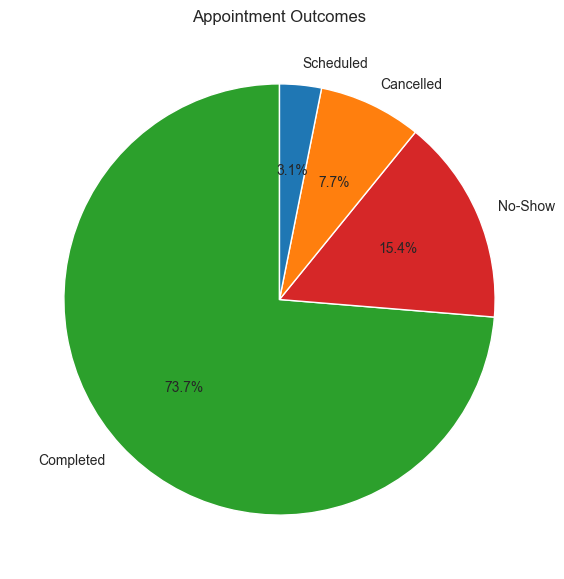

In [24]:
# Green = Completed, red = No-Show, orange = Cancelled, blue = Scheduled
status = df["appointment_status"].value_counts()
status_colors = {"Completed": "#2ca02c", "No-Show": "#d62728",
                 "Cancelled": "#ff7f0e", "Scheduled": "#1f77b4"}

print("Appointments by status:")
print(status)

plt.figure(figsize=(7, 7))
plt.pie(status, labels=status.index, autopct="%1.1f%%", startangle=90,
        colors=[status_colors[s] for s in status.index])
plt.title("Appointment Outcomes")
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• 73.7% of appointments were completed, 15.4% were no-shows and 7.7% were cancelled.<br>
• Excluding Scheduled, the no-show rate is 15.94%, so about 1 in 6 booked slots is wasted.
</div>

<div style="border-left:6px solid #d62728; padding:8px 14px;">
<b>Q3.</b> Which booking channels drive the highest volume and how does the channel mix look?
</div>

## 25. Booking Channel Volume

Appointments by booking channel:
booking_channel
Apollo App     34042
Website        18545
Call Centre    11201
Walk-In         7501
Partner App     3711
Name: count, dtype: int64


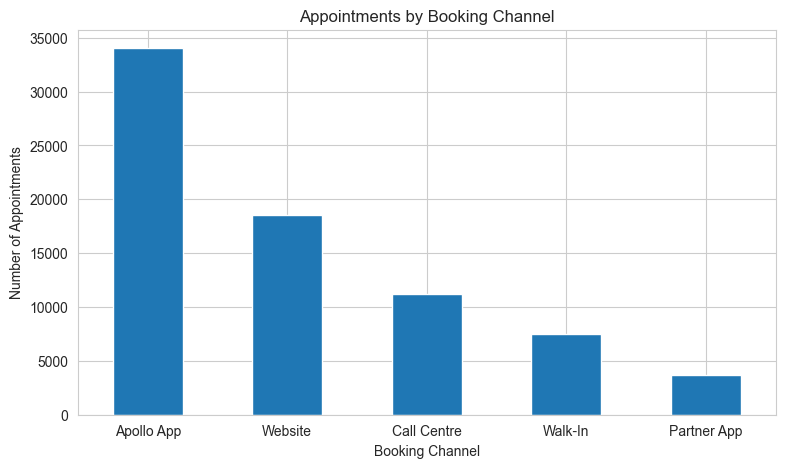

In [25]:
channel = df["booking_channel"].value_counts()

print("Appointments by booking channel:")
print(channel)

channel.plot(kind="bar", figsize=(9, 5), color="#1f77b4")
plt.title("Appointments by Booking Channel")
plt.xlabel("Booking Channel")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=0)
plt.show()

## 26. Booking Channel Share (%)

In [26]:
print("Share of appointments by booking channel (%):")
print((channel / channel.sum() * 100).round(1))

Share of appointments by booking channel (%):
booking_channel
Apollo App     45.4
Website        24.7
Call Centre    14.9
Walk-In        10.0
Partner App     4.9
Name: count, dtype: float64


## 27. Channel Mix by Year

Channel mix by year (%):
booking_channel   Apollo App  Call Centre  Partner App  Walk-In  Website
appointment_year                                                        
2022                    45.4         14.9          4.7     10.2     24.9
2023                    45.3         15.0          5.2      9.9     24.6
2024                    45.5         14.9          5.0      9.9     24.7


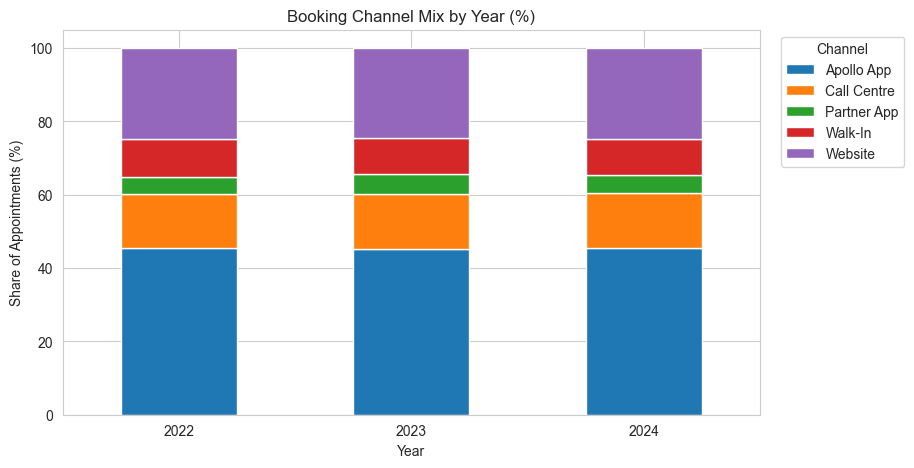

In [27]:
# Each year adds up to 100%
mix = pd.crosstab(df["appointment_year"], df["booking_channel"], normalize="index") * 100

print("Channel mix by year (%):")
print(mix.round(1))

mix.plot(kind="bar", stacked=True, figsize=(9, 5),
         color=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"])
plt.title("Booking Channel Mix by Year (%)")
plt.xlabel("Year")
plt.ylabel("Share of Appointments (%)")
plt.xticks(rotation=0)
plt.legend(title="Channel", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• Apollo App leads with 45.4% of bookings, then Website (24.7%) and Call Centre (14.9%). App and Website together bring about 70%.<br>
• The mix is almost identical in 2022, 2023 and 2024. Partner App is smallest (4.9%), so it is the main growth opportunity.
</div>

<hr style="border:3px solid #ff7f0e">

# PART 6: NO-SHOW ANALYSIS
<a id="part6"></a>

<div style="border-left:6px solid #ff7f0e; padding:8px 14px;">
<b>Q1.</b> Which specialties and cities have the highest and lowest no-show rates?
</div>

## 28. No-Show Rate by Specialty

In [28]:
# Overall rate is the baseline used in every chart below
overall = df_rate["no_show_flag"].mean() * 100

spec = df_rate.groupby("specialty")["no_show_flag"].agg(["mean", "count"])
spec["mean"] = spec["mean"] * 100
spec.columns = ["No-show rate (%)", "Appointments"]
spec = spec.sort_values("No-show rate (%)", ascending=False)

print("Overall no-show rate (%):", round(overall, 2))
print()
print("No-show rate by specialty:")
print(spec.round(2))

Overall no-show rate (%): 15.94

No-show rate by specialty:
                   No-show rate (%)  Appointments
specialty                                        
Psychiatry                    24.52          2900
Dermatology                   21.25          7566
ENT                           18.96          5211
Endocrinology                 17.54          2024
Ophthalmology                 16.21          3103
General Physician             15.51         19654
Pulmonology                   15.46          2549
Orthopaedics                  14.95          5419
Gastroenterology              14.92          2527
Urology                       14.40          2222
Gynaecology                   14.26          3991
Cardiology                    14.03          4484
Paediatrics                   12.22          6185
Neurology                     10.69          4817


## 29. Specialty Chart

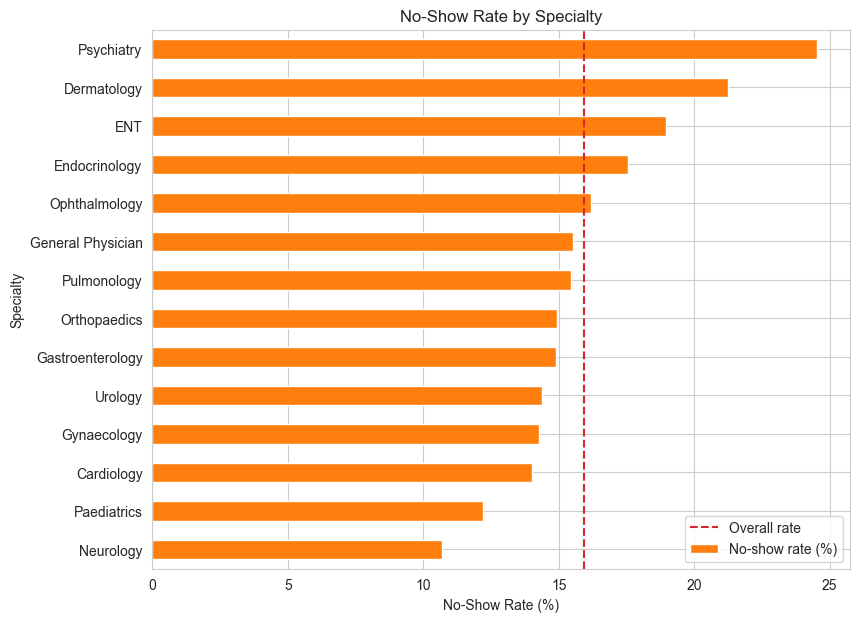

In [29]:
spec["No-show rate (%)"].sort_values().plot(kind="barh", figsize=(9, 7), color="#ff7f0e")
plt.axvline(overall, color="#d62728", linestyle="--", label="Overall rate")
plt.title("No-Show Rate by Specialty")
plt.xlabel("No-Show Rate (%)")
plt.ylabel("Specialty")
plt.legend()
plt.show()

## 30. Highest and Lowest Specialties

In [30]:
print("Top 3 highest no-show specialties:")
print(spec.head(3).round(2))
print()
print("Top 3 lowest no-show specialties:")
print(spec.tail(3).round(2))

Top 3 highest no-show specialties:
             No-show rate (%)  Appointments
specialty                                  
Psychiatry              24.52          2900
Dermatology             21.25          7566
ENT                     18.96          5211

Top 3 lowest no-show specialties:
             No-show rate (%)  Appointments
specialty                                  
Cardiology              14.03          4484
Paediatrics             12.22          6185
Neurology               10.69          4817


## 31. No-Show Rate by City

In [31]:
city = df_rate.groupby("city")["no_show_flag"].agg(["mean", "count"])
city["mean"] = city["mean"] * 100
city.columns = ["No-show rate (%)", "Appointments"]
city = city.sort_values("No-show rate (%)", ascending=False)

print("No-show rate by city:")
print(city.round(2))
print()
print("Highest city:", city.index[0], "-", round(city.iloc[0, 0], 2), "%")
print("Lowest city :", city.index[-1], "-", round(city.iloc[-1, 0], 2), "%")

No-show rate by city:
            No-show rate (%)  Appointments
city                                      
Lucknow                17.19          3001
Mumbai                 17.04          9734
Delhi                  16.86         10404
Bhopal                 16.79          2001
Kolkata                16.37          5701
Kochi                  16.28          2690
Ahmedabad              16.18          3468
Jaipur                 16.17          2653
Hyderabad              16.05          7229
Bengaluru              15.43          8343
Chandigarh             15.09          2406
Chennai                15.00          6702
Coimbatore             14.15          2162
Indore                 14.15          2149
Pune                   13.30          4009

Highest city: Lucknow - 17.19 %
Lowest city : Pune - 13.3 %


## 32. City Chart

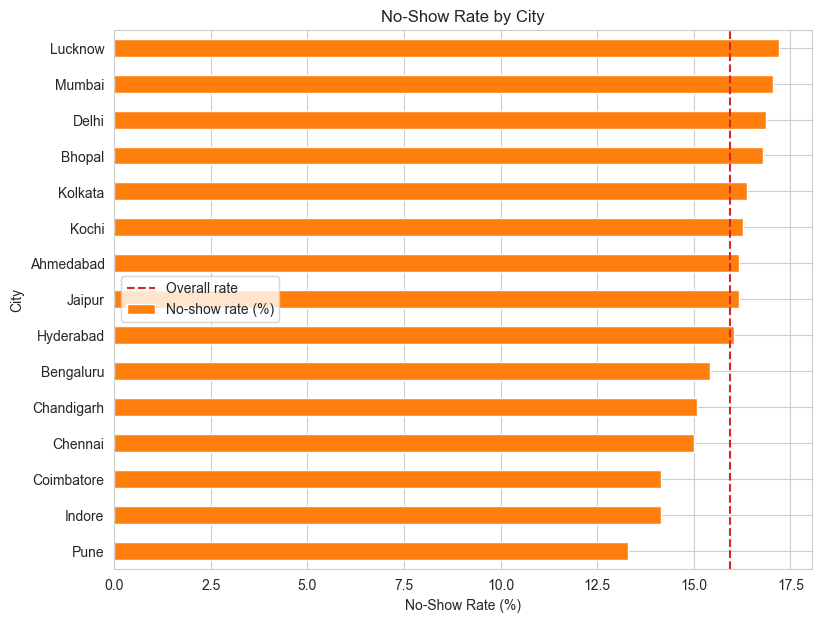

In [32]:
city["No-show rate (%)"].sort_values().plot(kind="barh", figsize=(9, 7), color="#ff7f0e")
plt.axvline(overall, color="#d62728", linestyle="--", label="Overall rate")
plt.title("No-Show Rate by City")
plt.xlabel("No-Show Rate (%)")
plt.ylabel("City")
plt.legend()
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• Psychiatry (24.5%), Dermatology (21.3%) and ENT (19.0%) have the highest no-show rates. Neurology (10.7%) and Paediatrics (12.2%) have the lowest.<br>
• Cities vary far less, from 13.3% in Pune to 17.2% in Lucknow, so the specialty matters more than the city. Target reminders at Psychiatry, Dermatology and ENT.
</div>

<div style="border-left:6px solid #ff7f0e; padding:8px 14px;">
<b>Q2.</b> How does booking lead time affect the probability of a no-show?
</div>

## 33. No-Show Rate by Lead Time (All Bookings)

In [33]:
lead = df_rate.groupby("lead_bucket", observed=True)["no_show_flag"].agg(["mean", "count"])
lead["mean"] = lead["mean"] * 100
lead.columns = ["No-show rate (%)", "Appointments"]

print("No-show rate by lead time group:")
print(lead.round(2))

No-show rate by lead time group:
             No-show rate (%)  Appointments
lead_bucket                                
Same day                15.82         20180
1-3                     14.33         25475
4-7                     16.50         15897
8-14                    18.82          8758
15-30                   20.03          2342


## 34. No-Show Rate by Lead Time (Without Walk-Ins)

In [34]:
# IMPORTANT: walk-ins have 0 lead days and cannot really book ahead, so they are removed here
no_walkin = df_rate[df_rate["booking_channel"] != "Walk-In"]

lead2 = no_walkin.groupby("lead_bucket", observed=True)["no_show_flag"].agg(["mean", "count"])
lead2["mean"] = lead2["mean"] * 100
lead2.columns = ["No-show rate (%)", "Appointments"]

print("No-show rate by lead time group (walk-ins removed):")
print(lead2.round(2))

No-show rate by lead time group (walk-ins removed):
             No-show rate (%)  Appointments
lead_bucket                                
Same day                12.97         12899
1-3                     14.33         25475
4-7                     16.50         15897
8-14                    18.82          8758
15-30                   20.03          2342


## 35. Lead Time Chart

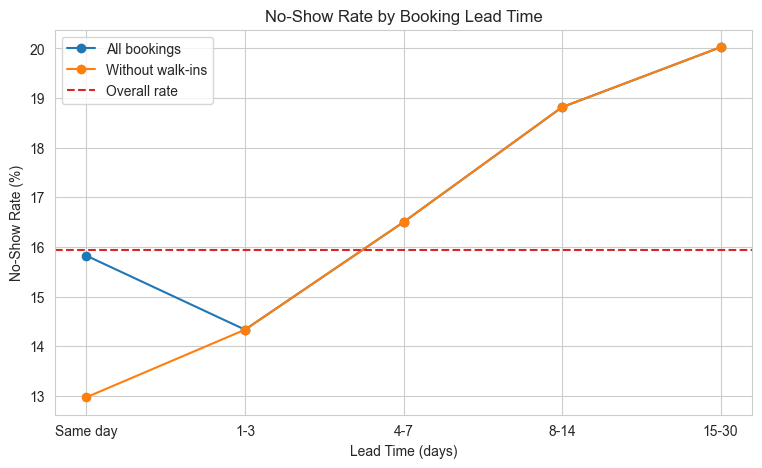

In [35]:
plt.figure(figsize=(9, 5))
plt.plot(lead.index.astype(str), lead["No-show rate (%)"], marker="o", color="#1f77b4", label="All bookings")
plt.plot(lead2.index.astype(str), lead2["No-show rate (%)"], marker="o", color="#ff7f0e", label="Without walk-ins")
plt.axhline(overall, color="#d62728", linestyle="--", label="Overall rate")
plt.title("No-Show Rate by Booking Lead Time")
plt.xlabel("Lead Time (days)")
plt.ylabel("No-Show Rate (%)")
plt.legend()
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b> 
</div>

<div style="border-left:6px solid #ff7f0e; padding:8px 14px;">
<b>Q3.</b> Do evening slots, weekends, and longer-lead bookings see higher dropout?
</div>

## 36. No-Show Rate by Time of Day

In [36]:
tod = df_rate.groupby("time_of_day")["no_show_flag"].agg(["mean", "count"])
tod["mean"] = tod["mean"] * 100
tod.columns = ["No-show rate (%)", "Appointments"]
tod = tod.reindex(["Morning", "Afternoon", "Evening"])

print("No-show rate by time of day:")
print(tod.round(2))

No-show rate by time of day:
             No-show rate (%)  Appointments
time_of_day                                
Morning                 13.73         34868
Afternoon               17.75         23231
Evening                 18.37         14553


## 37. No-Show Rate: Weekend vs Weekday

In [37]:
wk = df_rate.groupby("is_weekend")["no_show_flag"].agg(["mean", "count"])
wk["mean"] = wk["mean"] * 100
wk.columns = ["No-show rate (%)", "Appointments"]
wk.index = ["Weekday", "Weekend"]

print("No-show rate: weekday vs weekend:")
print(wk.round(2))

No-show rate: weekday vs weekend:
         No-show rate (%)  Appointments
Weekday             14.84         51731
Weekend             18.68         20921


## 38. No-Show Rate: Long Lead vs Short Lead

In [38]:
# Long lead = booked 15 or more days ahead, walk-ins removed
is_long = no_walkin["booking_lead_days"] >= 15
longlead = no_walkin.groupby(is_long)["no_show_flag"].agg(["mean", "count"])
longlead["mean"] = longlead["mean"] * 100
longlead.columns = ["No-show rate (%)", "Appointments"]
longlead.index = ["Under 15 days", "15+ days"]

print("No-show rate: short lead vs long lead:")
print(longlead.round(2))

No-show rate: short lead vs long lead:
               No-show rate (%)  Appointments
Under 15 days             15.22         63029
15+ days                  20.03          2342


## 39. Comparison Chart

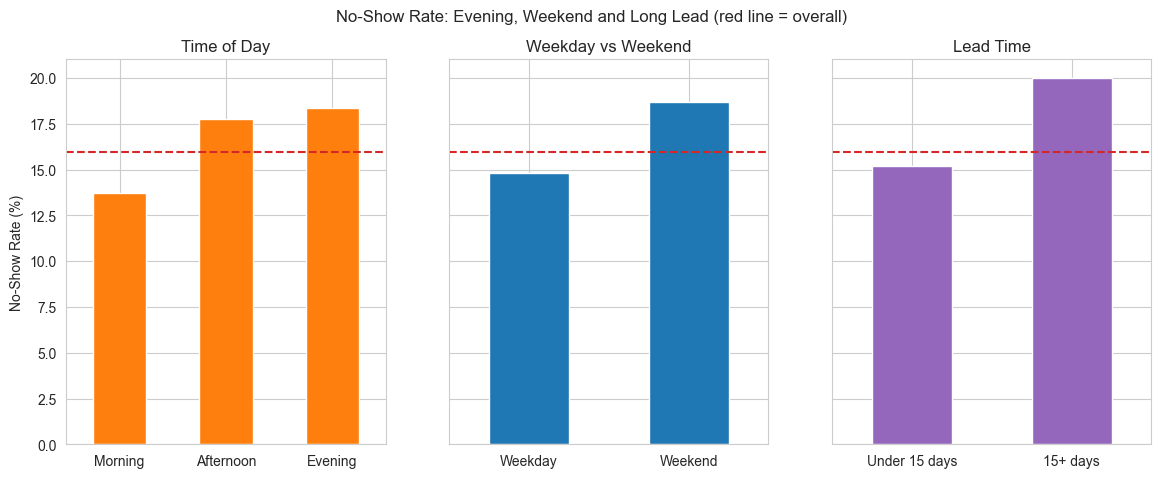

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)

tod["No-show rate (%)"].plot(kind="bar", ax=axes[0], color="#ff7f0e")
axes[0].set_title("Time of Day")

wk["No-show rate (%)"].plot(kind="bar", ax=axes[1], color="#1f77b4")
axes[1].set_title("Weekday vs Weekend")

longlead["No-show rate (%)"].plot(kind="bar", ax=axes[2], color="#9467bd")
axes[2].set_title("Lead Time")

for ax in axes:
    ax.axhline(overall, color="#d62728", linestyle="--")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("No-Show Rate (%)")
plt.suptitle("No-Show Rate: Evening, Weekend and Long Lead (red line = overall)")
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• No-show rate rises steadily with lead time: about 13% for same-day bookings, 14% for 1-3 days, 16.5% for 4-7 days, 19% for 8-14 days and 20% for 15-30 days.<br>
• Bookings made 8 or more days ahead cross the overall 15.94% line, so Apollo should send extra reminders to them.
</div>

<div style="border-left:6px solid #ff7f0e; padding:8px 14px;">
<b>Q4.</b> Which appointment types and booking channels carry the most no-show risk?
</div>

## 40. No-Show Rate by Appointment Type

In [40]:
atype = df_rate.groupby("appointment_type")["no_show_flag"].agg(["mean", "count"])
atype["mean"] = atype["mean"] * 100
atype.columns = ["No-show rate (%)", "Appointments"]
atype = atype.sort_values("No-show rate (%)", ascending=False)

print("No-show rate by appointment type:")
print(atype.round(2))

No-show rate by appointment type:
                  No-show rate (%)  Appointments
appointment_type                                
Home Visit                   26.25          9742
Video Consult                21.06         15349
In-Clinic                    12.18         47561


## 41. No-Show Rate by Booking Channel

In [41]:
chan = df_rate.groupby("booking_channel")["no_show_flag"].agg(["mean", "count"])
chan["mean"] = chan["mean"] * 100
chan.columns = ["No-show rate (%)", "Appointments"]
chan = chan.sort_values("No-show rate (%)", ascending=False)

print("No-show rate by booking channel:")
print(chan.round(2))

No-show rate by booking channel:
                 No-show rate (%)  Appointments
booking_channel                                
Walk-In                     20.88          7281
Partner App                 18.11          3594
Website                     17.20         17964
Call Centre                 15.20         10855
Apollo App                  14.18         32958


## 42. Appointment Type and Channel Chart

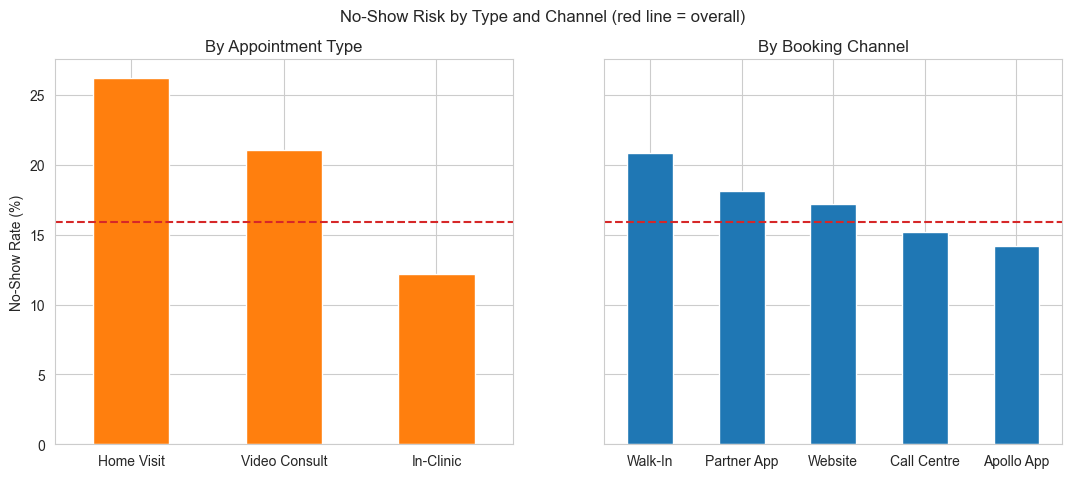

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

atype["No-show rate (%)"].plot(kind="bar", ax=axes[0], color="#ff7f0e")
axes[0].set_title("By Appointment Type")

chan["No-show rate (%)"].plot(kind="bar", ax=axes[1], color="#1f77b4")
axes[1].set_title("By Booking Channel")

for ax in axes:
    ax.axhline(overall, color="#d62728", linestyle="--")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("No-Show Rate (%)")
plt.suptitle("No-Show Risk by Type and Channel (red line = overall)")
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• Home Visits (about 26%) and Video Consults (about 21%) are far riskier than In-Clinic (about 12%). Walk-In (about 21%) and Partner App (about 18%) are the riskiest channels.<br>
• Apollo App (about 14%) and Call Centre (about 15%) are the safest. Add stronger reminders or a small deposit for Home Visit and Video Consult bookings.
</div>

<hr style="border:3px solid #1f77b4">

# PART 7: REMINDER AND ENGAGEMENT EFFECTIVENESS
<a id="part7"></a>

<div style="border-left:6px solid #1f77b4; padding:8px 14px;">
<b>Q1.</b> How much does reminder type reduce no-show rates compared to no-reminder patients?
</div>

## 43. No-Show Rate by Reminder Type

In [43]:
rem = df_rate.groupby("reminder_type")["no_show_flag"].agg(["mean", "count"])
rem["mean"] = rem["mean"] * 100
rem.columns = ["No-show rate (%)", "Appointments"]
rem = rem.sort_values("No-show rate (%)", ascending=False)

print("No-show rate by reminder type:")
print(rem.round(2))

No-show rate by reminder type:
                       No-show rate (%)  Appointments
reminder_type                                        
No Reminder                       30.16         10977
SMS Only                          16.27         14527
SMS + WhatsApp                    13.51         25273
SMS + WhatsApp + Call             11.41         21875


## 44. No-Show Rate by Number of Reminders

In [44]:
# IMPORTANT: 0 reminders = no-reminder group, used as the baseline
nrem = df_rate.groupby("reminders_sent")["no_show_flag"].agg(["mean", "count"])
nrem["mean"] = nrem["mean"] * 100
nrem.columns = ["No-show rate (%)", "Appointments"]

print("No-show rate by number of reminders sent:")
print(nrem.round(2))

No-show rate by number of reminders sent:
                No-show rate (%)  Appointments
reminders_sent                                
0                          30.16         10977
1                          16.27         14527
2                          13.51         25273
3                          11.41         21875


## 45. Reduction Compared to No Reminder

In [45]:
baseline = nrem.loc[0, "No-show rate (%)"]
nrem["Reduction vs no reminder (%)"] = (baseline - nrem["No-show rate (%)"]) / baseline * 100

print("No-reminder no-show rate (%):", round(baseline, 2))
print()
print("Reduction compared to no reminder:")
print(nrem[["No-show rate (%)", "Reduction vs no reminder (%)"]].round(2))

No-reminder no-show rate (%): 30.16

Reduction compared to no reminder:
                No-show rate (%)  Reduction vs no reminder (%)
reminders_sent                                                
0                          30.16                          0.00
1                          16.27                         46.07
2                          13.51                         55.22
3                          11.41                         62.17


## 46. Reminder Chart

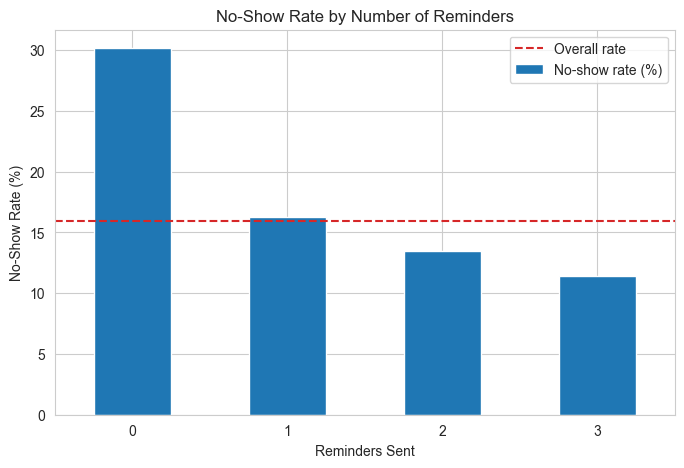

In [46]:
nrem["No-show rate (%)"].plot(kind="bar", figsize=(8, 5), color="#1f77b4")
plt.axhline(overall, color="#d62728", linestyle="--", label="Overall rate")
plt.title("No-Show Rate by Number of Reminders")
plt.xlabel("Reminders Sent")
plt.ylabel("No-Show Rate (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• No-show rate falls with every extra reminder: about 30% with none, 16% with one, 13% with two and 11% with all three. That is roughly a 63% drop from no reminder to the full bundle.<br>
• Patients with no reminder are almost twice as likely as average to miss, so Apollo should send at least one reminder to every booking.
</div>

<div style="border-left:6px solid #1f77b4; padding:8px 14px;">
<b>Q2.</b> Does prior no-show history predict future no-show behaviour?
</div>

## 47. No-Show Rate by Prior No-Shows

In [47]:
# Prior no-shows of 3 or more are grouped together as "3+"
prior = df_rate["patient_prior_no_shows"].clip(upper=3)

prior_tbl = df_rate.groupby(prior)["no_show_flag"].agg(["mean", "count"])
prior_tbl["mean"] = prior_tbl["mean"] * 100
prior_tbl.columns = ["No-show rate (%)", "Appointments"]
prior_tbl.index = prior_tbl.index.map(lambda x: "3+" if x == 3 else str(x))

print("No-show rate by number of prior no-shows:")
print(prior_tbl.round(2))

No-show rate by number of prior no-shows:
                        No-show rate (%)  Appointments
patient_prior_no_shows                                
0                                  15.15         63014
1                                  20.27          8502
2                                  26.65           983
3+                                 32.68           153


## 48. Correlation with Prior No-Shows

In [48]:
corr = df_rate["patient_prior_no_shows"].corr(df_rate["no_show_flag"])
print("Correlation (prior no-shows vs no-show):", round(corr, 3))

Correlation (prior no-shows vs no-show): 0.06


## 49. Prior No-Show Chart

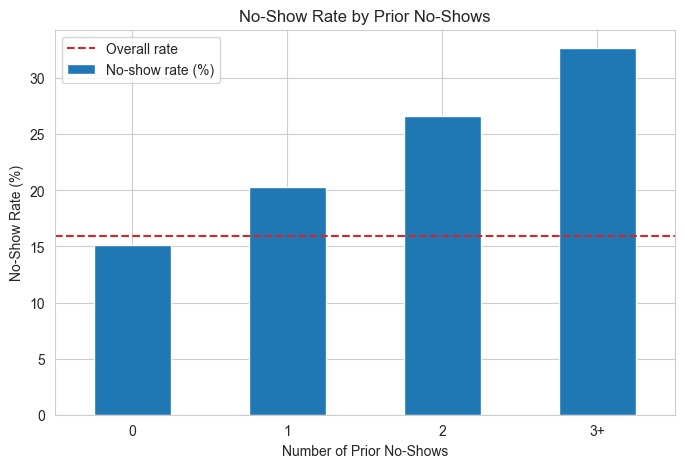

In [49]:
prior_tbl["No-show rate (%)"].plot(kind="bar", figsize=(8, 5), color="#1f77b4")
plt.axhline(overall, color="#d62728", linestyle="--", label="Overall rate")
plt.title("No-Show Rate by Prior No-Shows")
plt.xlabel("Number of Prior No-Shows")
plt.ylabel("No-Show Rate (%)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• Past behaviour predicts future behaviour: the no-show rate rises from about 15% with no prior no-shows to 20% with one, 27% with two and 33% with three or more.<br>
• Patients with 2 or more prior no-shows miss almost twice as often as average, so flag them for extra reminders or a confirmation call.
</div>

<div style="border-left:6px solid #1f77b4; padding:8px 14px;">
<b>Q3.</b> Do Apollo members and repeat patients show better attendance than non-members and first-time patients?
</div>

## 50. Check Repeat Visit Columns

In [50]:
# is_first_visit and repeat_visit should agree (1 = first visit = "No")
print("is_first_visit vs repeat_visit:")
print(pd.crosstab(df_rate["is_first_visit"], df_rate["repeat_visit"]))

is_first_visit vs repeat_visit:
repeat_visit      No    Yes
is_first_visit             
0                  0  63470
1               9182      0


## 51. No-Show Rate: Members vs Non-Members

In [51]:
mem = df_rate.groupby("apollo_member")["no_show_flag"].agg(["mean", "count"])
mem["mean"] = mem["mean"] * 100
mem.columns = ["No-show rate (%)", "Appointments"]

print("No-show rate: Apollo members vs non-members:")
print(mem.round(2))
print()

tier = df_rate.groupby("membership_type")["no_show_flag"].agg(["mean", "count"])
tier["mean"] = tier["mean"] * 100
tier.columns = ["No-show rate (%)", "Appointments"]

print("No-show rate by membership type:")
print(tier.round(2))

No-show rate: Apollo members vs non-members:
               No-show rate (%)  Appointments
apollo_member                                
No                        16.89         56428
Yes                       12.66         16224

No-show rate by membership type:
                 No-show rate (%)  Appointments
membership_type                                
Apollo Gold                 12.65          8167
Apollo Silver               12.67          8057
None                        16.89         56428


## 52. No-Show Rate: Repeat vs First-Time Patients

In [52]:
rep = df_rate.groupby("repeat_visit")["no_show_flag"].agg(["mean", "count"])
rep["mean"] = rep["mean"] * 100
rep.columns = ["No-show rate (%)", "Appointments"]

print("No-show rate: repeat (Yes) vs first-time (No) patients:")
print(rep.round(2))

No-show rate: repeat (Yes) vs first-time (No) patients:
              No-show rate (%)  Appointments
repeat_visit                                
No                       66.78          9182
Yes                       8.59         63470


## 53. Members and Repeat Patients Chart

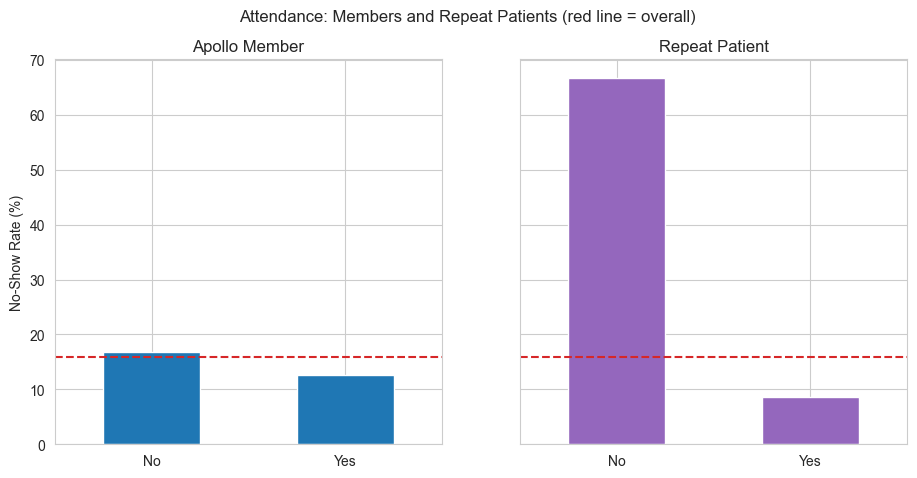

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

mem["No-show rate (%)"].plot(kind="bar", ax=axes[0], color="#1f77b4")
axes[0].set_title("Apollo Member")

rep["No-show rate (%)"].plot(kind="bar", ax=axes[1], color="#9467bd")
axes[1].set_title("Repeat Patient")

for ax in axes:
    ax.axhline(overall, color="#d62728", linestyle="--")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("No-Show Rate (%)")
plt.suptitle("Attendance: Members and Repeat Patients (red line = overall)")
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• Repeat patients miss only 8.6% of appointments, while first-time patients miss 66.8%. Apollo members also miss less than non-members (about 12% vs 17%).<br>
• First-time patients are the biggest risk group, so send them extra reminders and a confirmation call.
</div>

<hr style="border:3px solid #9467bd">

# PART 8: PATIENT AND DEMOGRAPHIC SEGMENTATION
<a id="part8"></a>

<div style="border-left:6px solid #9467bd; padding:8px 14px;">
<b>Q1.</b> How do age group, gender, and chronic condition status influence no-show likelihood?
</div>

## 54. No-Show Rate by Age Group

In [54]:
# Age groups are sorted from youngest to oldest using each group's minimum age
age_order = df.groupby("age_group")["patient_age"].min().sort_values().index

age = df_rate.groupby("age_group")["no_show_flag"].agg(["mean", "count"])
age["mean"] = age["mean"] * 100
age.columns = ["No-show rate (%)", "Appointments"]
age = age.reindex(age_order)

print("No-show rate by age group:")
print(age.round(2))

No-show rate by age group:
                     No-show rate (%)  Appointments
age_group                                          
Child (0-12)                    13.54         11745
Teen (13-18)                    14.72          6379
Young Adult (19-30)             17.94         10017
Adult (31-45)                   18.05         15133
Middle-aged (46-60)             16.76         14862
Senior (60+)                    14.03         14516


## 55. No-Show Rate by Gender

In [55]:
gender = df_rate.groupby("patient_gender")["no_show_flag"].agg(["mean", "count"])
gender["mean"] = gender["mean"] * 100
gender.columns = ["No-show rate (%)", "Appointments"]

print("No-show rate by gender:")
print(gender.round(2))

No-show rate by gender:
                No-show rate (%)  Appointments
patient_gender                                
Female                     16.04         37589
Male                       15.84         35063


## 56. No-Show Rate by Chronic Condition

In [56]:
# "None" means the patient has no chronic condition (a valid category, not missing)
chronic = df_rate.groupby("patient_chronic_condition")["no_show_flag"].agg(["mean", "count"])
chronic["mean"] = chronic["mean"] * 100
chronic.columns = ["No-show rate (%)", "Appointments"]
chronic = chronic.sort_values("No-show rate (%)", ascending=False)

print("No-show rate by chronic condition:")
print(chronic.round(2))

No-show rate by chronic condition:
                           No-show rate (%)  Appointments
patient_chronic_condition                                
Asthma                                16.71          9098
Heart Disease                         16.32          9155
None                                  15.89         27144
Diabetes                              15.77          9010
Hypertension                          15.57          9100
Hypothyroidism                        15.51          9145


## 57. Age, Gender and Chronic Condition Chart

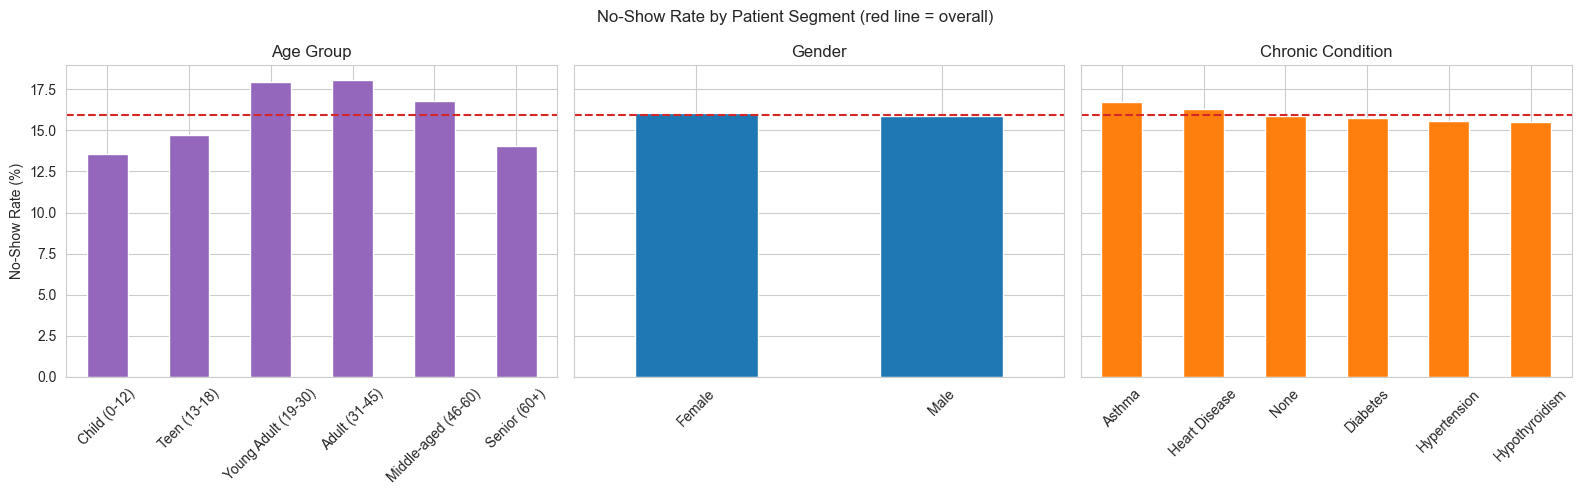

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

age["No-show rate (%)"].plot(kind="bar", ax=axes[0], color="#9467bd")
axes[0].set_title("Age Group")

gender["No-show rate (%)"].plot(kind="bar", ax=axes[1], color="#1f77b4")
axes[1].set_title("Gender")

chronic["No-show rate (%)"].plot(kind="bar", ax=axes[2], color="#ff7f0e")
axes[2].set_title("Chronic Condition")

for ax in axes:
    ax.axhline(overall, color="#d62728", linestyle="--")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("No-Show Rate (%)")
plt.suptitle("No-Show Rate by Patient Segment (red line = overall)")
plt.tight_layout()
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• Age matters most: Young Adults (19-30) and Adults (31-45) miss about 18%, while Children (0-12) and Seniors (60+) miss only about 13-14%.<br>
• Gender and chronic condition make almost no difference (all close to 16%), so target reminders by age group instead.
</div>

<div style="border-left:6px solid #9467bd; padding:8px 14px;">
<b>Q2.</b> Which visit reasons are most common and are some associated with higher dropout?
</div>

## 58. Most Common Visit Reasons

In [58]:
reasons = df["visit_reason"].value_counts()

print("Appointments by visit reason:")
print(reasons)

Appointments by visit reason:
visit_reason
Follow-up                       8807
Routine Checkup                 8637
Chronic Condition Management    8380
Digestive Problem               8245
Fever & Infection               7041
Joint Pain                      6664
Respiratory Issue               6590
Injury                          6087
Eye Care                        2959
Skin Issue                      2862
Mental Health                   2830
Cardiac Concern                 2708
Women's Health                  2449
Child Health                     741
Name: count, dtype: int64


## 59. No-Show Rate by Visit Reason

In [59]:
vr = df_rate.groupby("visit_reason")["no_show_flag"].agg(["mean", "count"])
vr["mean"] = vr["mean"] * 100
vr.columns = ["No-show rate (%)", "Appointments"]
vr = vr.sort_values("No-show rate (%)", ascending=False)

print("No-show rate by visit reason:")
print(vr.round(2))

No-show rate by visit reason:
                              No-show rate (%)  Appointments
visit_reason                                                
Skin Issue                               16.79          2782
Joint Pain                               16.73          6469
Cardiac Concern                          16.29          2639
Mental Health                            16.28          2733
Digestive Problem                        16.24          7984
Injury                                   16.13          5884
Fever & Infection                        16.08          6808
Respiratory Issue                        15.98          6383
Women's Health                           15.96          2362
Routine Checkup                          15.63          8377
Chronic Condition Management             15.60          8117
Eye Care                                 15.48          2869
Follow-up                                15.22          8528
Child Health                             14.64         

## 60. Visit Reason Charts

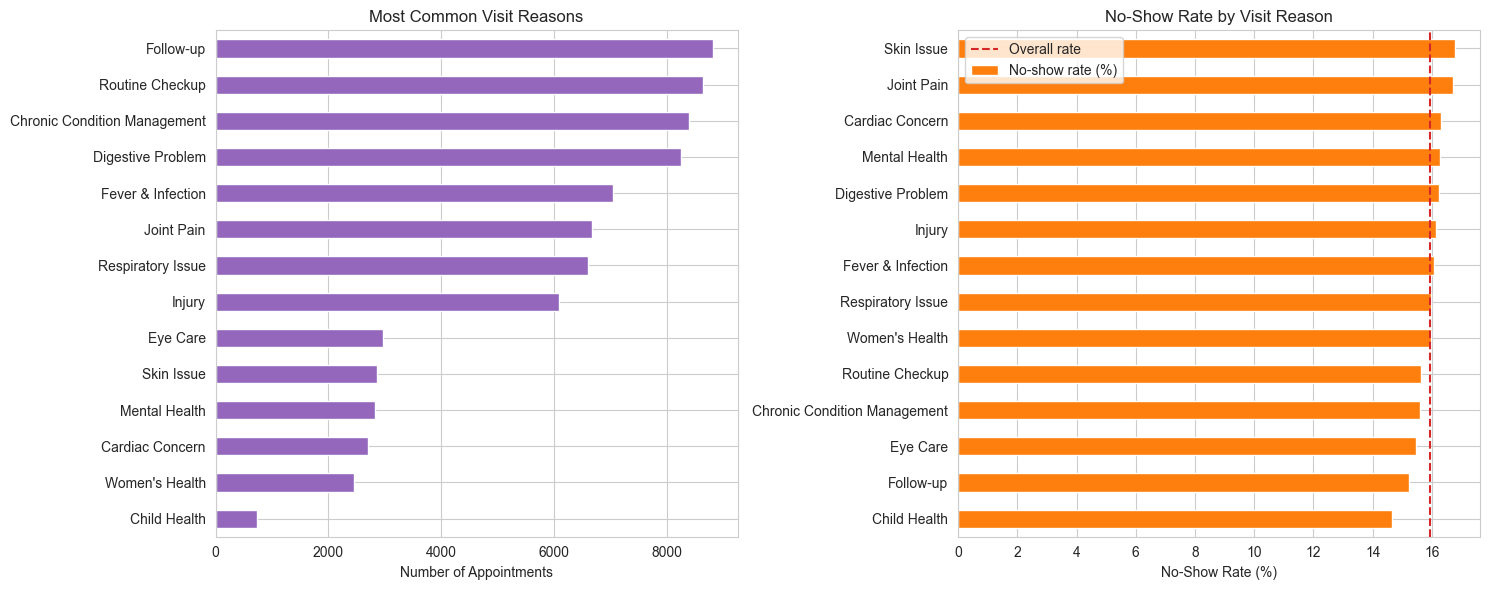

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

reasons.sort_values().plot(kind="barh", ax=axes[0], color="#9467bd")
axes[0].set_title("Most Common Visit Reasons")
axes[0].set_xlabel("Number of Appointments")
axes[0].set_ylabel("")

vr["No-show rate (%)"].sort_values().plot(kind="barh", ax=axes[1], color="#ff7f0e")
axes[1].axvline(overall, color="#d62728", linestyle="--", label="Overall rate")
axes[1].set_title("No-Show Rate by Visit Reason")
axes[1].set_xlabel("No-Show Rate (%)")
axes[1].set_ylabel("")
axes[1].legend()

plt.tight_layout()
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• Follow-up, Routine Checkup and Chronic Condition Management are the most common reasons (about 8,500 to 8,800 each). Child Health and Women's Health are the least common.<br>
• Dropout barely changes by reason (about 15% to 17%), with Skin Issue and Joint Pain slightly highest and Follow-up and Child Health lowest, so visit reason is a weak predictor.
</div>

<div style="border-left:6px solid #9467bd; padding:8px 14px;">
<b>Q3.</b> What does the patient age distribution look like within specialties like Paediatrics, Gynaecology, and Psychiatry?
</div>

## 61. Check Specialty Spellings

In [61]:
# IMPORTANT: names must match exactly, so check they exist before filtering
chosen = ["Paediatrics", "Gynaecology", "Psychiatry"]

print("Specialties in the data:")
print(sorted(df["specialty"].unique()))
print()
print("Chosen specialties found:", [s for s in chosen if s in df["specialty"].values])

Specialties in the data:
['Cardiology', 'Dermatology', 'ENT', 'Endocrinology', 'Gastroenterology', 'General Physician', 'Gynaecology', 'Neurology', 'Ophthalmology', 'Orthopaedics', 'Paediatrics', 'Psychiatry', 'Pulmonology', 'Urology']

Chosen specialties found: ['Paediatrics', 'Gynaecology', 'Psychiatry']


## 62. Age Summary for These Specialties

In [62]:
three = df[df["specialty"].isin(chosen)]

print("Patient age summary:")
print(three.groupby("specialty")["patient_age"].describe().round(1))

Patient age summary:
              count  mean   std  min   25%   50%   75%   max
specialty                                                   
Gynaecology  4113.0  41.7  21.7  1.0  25.0  42.0  59.0  85.0
Paediatrics  6382.0   9.3   5.0  1.0   5.0   9.0  14.0  18.0
Psychiatry   2989.0  42.0  21.7  1.0  25.0  42.0  59.0  85.0


## 63. Age Distribution Charts

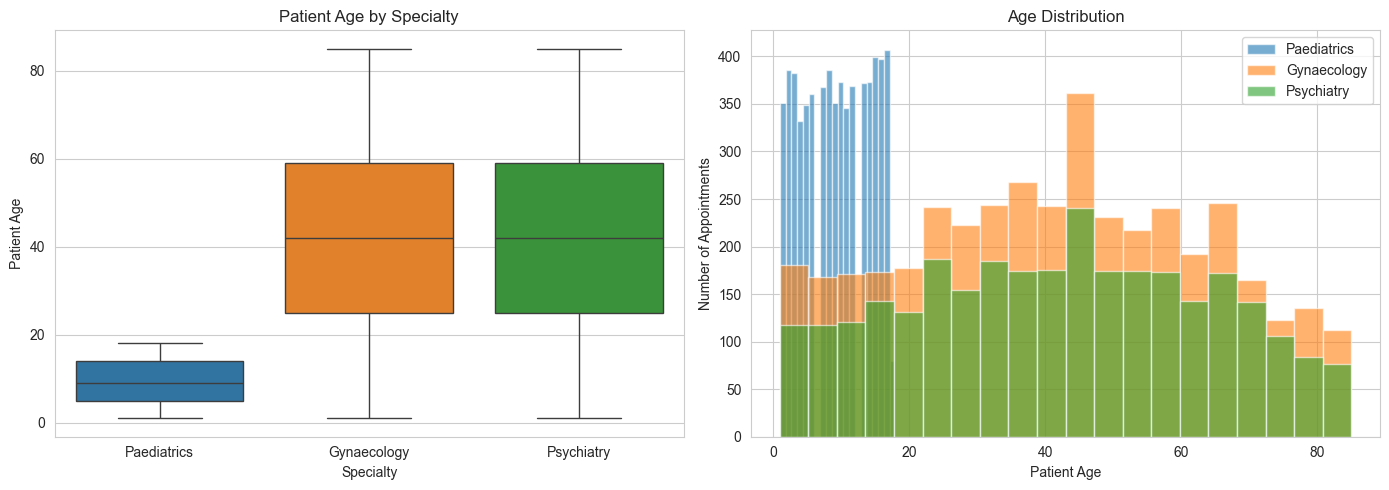

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=three, x="specialty", y="patient_age", order=chosen,
            palette=["#1f77b4", "#ff7f0e", "#2ca02c"], ax=axes[0])
axes[0].set_title("Patient Age by Specialty")
axes[0].set_xlabel("Specialty")
axes[0].set_ylabel("Patient Age")

for name, colour in zip(chosen, ["#1f77b4", "#ff7f0e", "#2ca02c"]):
    axes[1].hist(three[three["specialty"] == name]["patient_age"],
                 bins=20, alpha=0.6, color=colour, label=name)
axes[1].set_title("Age Distribution")
axes[1].set_xlabel("Patient Age")
axes[1].set_ylabel("Number of Appointments")
axes[1].legend()

plt.tight_layout()
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• Paediatrics patients are almost all children, mostly under 18 with a median age of about 9. Gynaecology and Psychiatry cover adults of all ages, with a median around 42 and most patients between 25 and 60.<br>
• Gynaecology and Psychiatry look almost the same in age, so one adult-focused reminder plan can serve both, while Paediatrics reminders should go to parents.
</div>

<hr style="border:3px solid #2ca02c">

# PART 9: FINANCIAL PERFORMANCE
<a id="part9"></a>

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Q1.</b> How much revenue is being lost to no-shows?
</div>

## 64. Estimate Revenue Lost to No-Shows

In [64]:
# IMPORTANT: revenue is 0 for no-shows, so lost revenue is an ESTIMATE
# Estimate 1 = no-shows x average revenue of a completed visit (same specialty)
# Estimate 2 = no-shows x listed consultation fee
noshows = df_rate[df_rate["no_show_flag"] == 1]
avg_rev = df_comp.groupby("specialty")["revenue_realized"].mean()

est_loss = noshows["specialty"].map(avg_rev).sum()
fee_loss = noshows["consultation_fee"].sum()
total_rev = df_comp["revenue_realized"].sum()

print("Number of no-shows         :", len(noshows))
print("Revenue earned (Completed) :", f"{total_rev:,.0f}")
print("Lost revenue (avg revenue) :", f"{est_loss:,.0f}")
print("Lost revenue (listed fee)  :", f"{fee_loss:,.0f}")
print("Lost as % of revenue earned:", round(est_loss / total_rev * 100, 2), "%")

Number of no-shows         : 11584
Revenue earned (Completed) : 73,893,798
Lost revenue (avg revenue) : 15,656,319
Lost revenue (listed fee)  : 19,725,460
Lost as % of revenue earned: 21.19 %


## 65. Lost Revenue by Specialty

Estimated lost revenue by specialty:
specialty
Dermatology          2101531.0
General Physician    1929389.0
Psychiatry           1877358.0
Orthopaedics         1253230.0
Cardiology           1220741.0
ENT                  1190023.0
Neurology            1069387.0
Gynaecology           853268.0
Ophthalmology         737964.0
Paediatrics           717993.0
Gastroenterology      715100.0
Pulmonology           710472.0
Endocrinology         643503.0
Urology               636359.0
dtype: float64


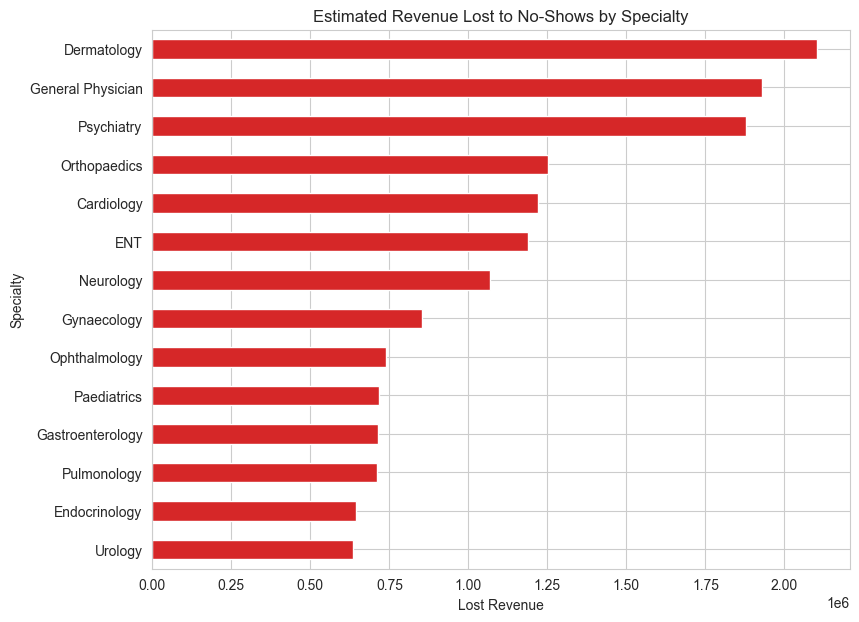

In [65]:
lost_spec = (noshows.groupby("specialty").size() * avg_rev).sort_values(ascending=False)

print("Estimated lost revenue by specialty:")
print(lost_spec.round(0))

lost_spec.sort_values().plot(kind="barh", figsize=(9, 7), color="#d62728")
plt.title("Estimated Revenue Lost to No-Shows by Specialty")
plt.xlabel("Lost Revenue")
plt.ylabel("Specialty")
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• No-shows cost an estimated 15.7M (average revenue) to 19.7M (listed fee), about 21% of the 73.9M revenue earned. Dermatology, General Physician and Psychiatry lose the most.<br>
• Lost revenue depends on both no-show rate and booking volume, so prioritise reminders for these three specialties.
</div>

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Q2.</b> How does average revenue vary across specialties and appointment types?
</div>

## 66. Average Revenue by Specialty

In [66]:
rev_spec = df_comp.groupby("specialty")["revenue_realized"].agg(["mean", "count"])
rev_spec.columns = ["Avg revenue", "Appointments"]
rev_spec = rev_spec.sort_values("Avg revenue", ascending=False)

print("Average revenue per completed appointment by specialty:")
print(rev_spec.round(0))

Average revenue per completed appointment by specialty:
                   Avg revenue  Appointments
specialty                                   
Psychiatry              2640.0          1958
Neurology               2076.0          3899
Urology                 1989.0          1729
Cardiology              1941.0          3507
Gastroenterology        1897.0          1972
Endocrinology           1813.0          1504
Pulmonology             1803.0          1961
Orthopaedics            1547.0          4189
Gynaecology             1500.0          3134
Ophthalmology           1467.0          2349
Dermatology             1307.0          5347
ENT                     1204.0          3845
Paediatrics              950.0          4900
General Physician        633.0         14981


## 67. Average Revenue by Appointment Type

In [67]:
rev_type = df_comp.groupby("appointment_type")["revenue_realized"].agg(["mean", "count"])
rev_type.columns = ["Avg revenue", "Appointments"]
rev_type = rev_type.sort_values("Avg revenue", ascending=False)

print("Average revenue per completed appointment by type:")
print(rev_type.round(0))

Average revenue per completed appointment by type:
                  Avg revenue  Appointments
appointment_type                           
Home Visit             1960.0          6436
In-Clinic              1300.0         37938
Video Consult          1098.0         10901


## 68. Average Revenue Charts

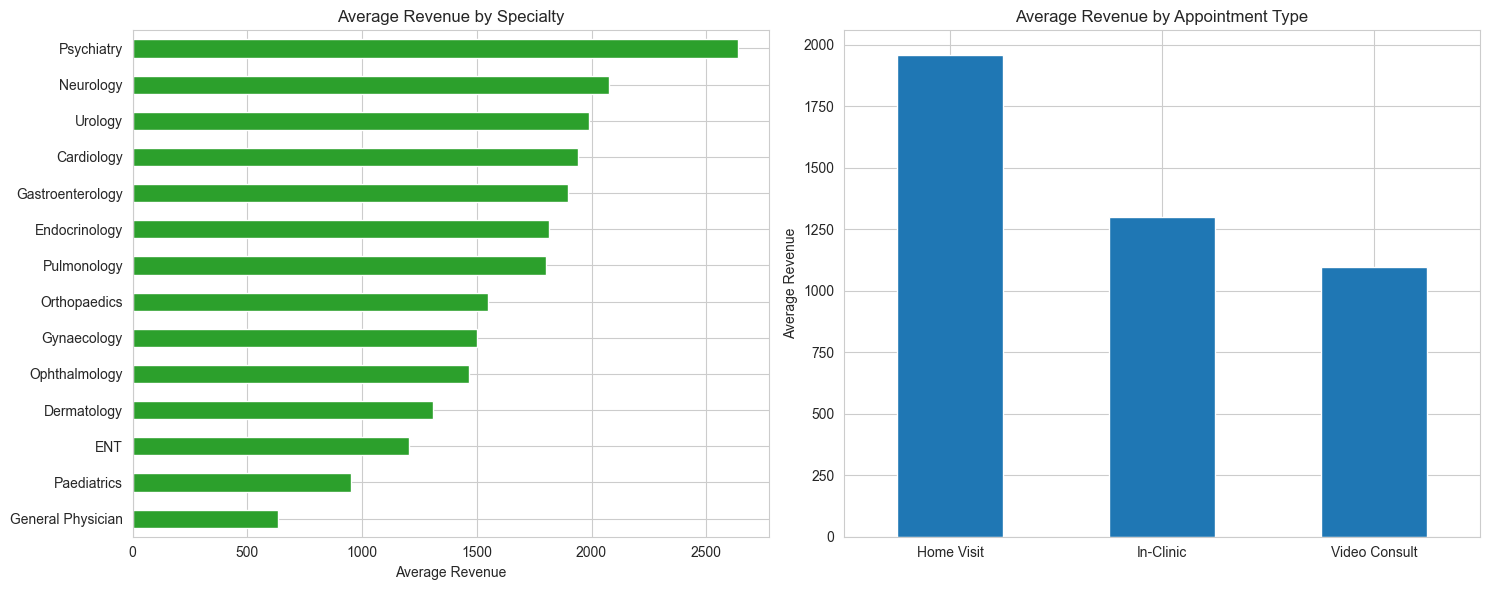

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

rev_spec["Avg revenue"].sort_values().plot(kind="barh", ax=axes[0], color="#2ca02c")
axes[0].set_title("Average Revenue by Specialty")
axes[0].set_xlabel("Average Revenue")
axes[0].set_ylabel("")

rev_type["Avg revenue"].plot(kind="bar", ax=axes[1], color="#1f77b4")
axes[1].set_title("Average Revenue by Appointment Type")
axes[1].set_xlabel("")
axes[1].set_ylabel("Average Revenue")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• Psychiatry (about 2,600) earns the most per completed visit, followed by Neurology and Urology (about 2,000). General Physician (about 650) and Paediatrics (about 950) earn the least. Home Visits (about 1,950) earn far more than In-Clinic (about 1,300) and Video Consults (about 1,100).<br>
• Home Visits and Psychiatry are the highest-value appointments, so protecting those slots from no-shows gives the biggest revenue return.
</div>

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Q3.</b> Which cities generate the most revenue and what is the payment mode mix?
</div>

## 69. Total Revenue by City

In [69]:
rev_city = df_comp.groupby("city")["revenue_realized"].sum().sort_values(ascending=False)

print("Total revenue by city:")
print(rev_city)
print()
print("Top city   :", rev_city.index[0])
print("Share of top 3 cities (%):", round(rev_city.head(3).sum() / rev_city.sum() * 100, 1))

Total revenue by city:
city
Bengaluru     9990616
Delhi         9958247
Mumbai        8989613
Hyderabad     7503245
Chennai       7188473
Kolkata       6543084
Pune          4734139
Ahmedabad     3956890
Lucknow       3177444
Indore        2223207
Chandigarh    2221091
Jaipur        2199116
Coimbatore    1792804
Kochi         1731448
Bhopal        1684381
Name: revenue_realized, dtype: int64

Top city   : Bengaluru
Share of top 3 cities (%): 39.2


## 70. Payment Mode Mix

In [70]:
pay = df_comp["payment_mode"].value_counts()

print("Appointments by payment mode:")
print(pay)
print()
print("Payment mode share (%):")
print((pay / pay.sum() * 100).round(1))

Appointments by payment mode:
payment_mode
Insurance      11641
Debit Card      7353
Net Banking     7349
Apollo Pay      7324
UPI             7259
Credit Card     7213
Cash            7136
Name: count, dtype: int64

Payment mode share (%):
payment_mode
Insurance      21.1
Debit Card     13.3
Net Banking    13.3
Apollo Pay     13.3
UPI            13.1
Credit Card    13.0
Cash           12.9
Name: count, dtype: float64


## 71. City Revenue and Payment Mode Charts

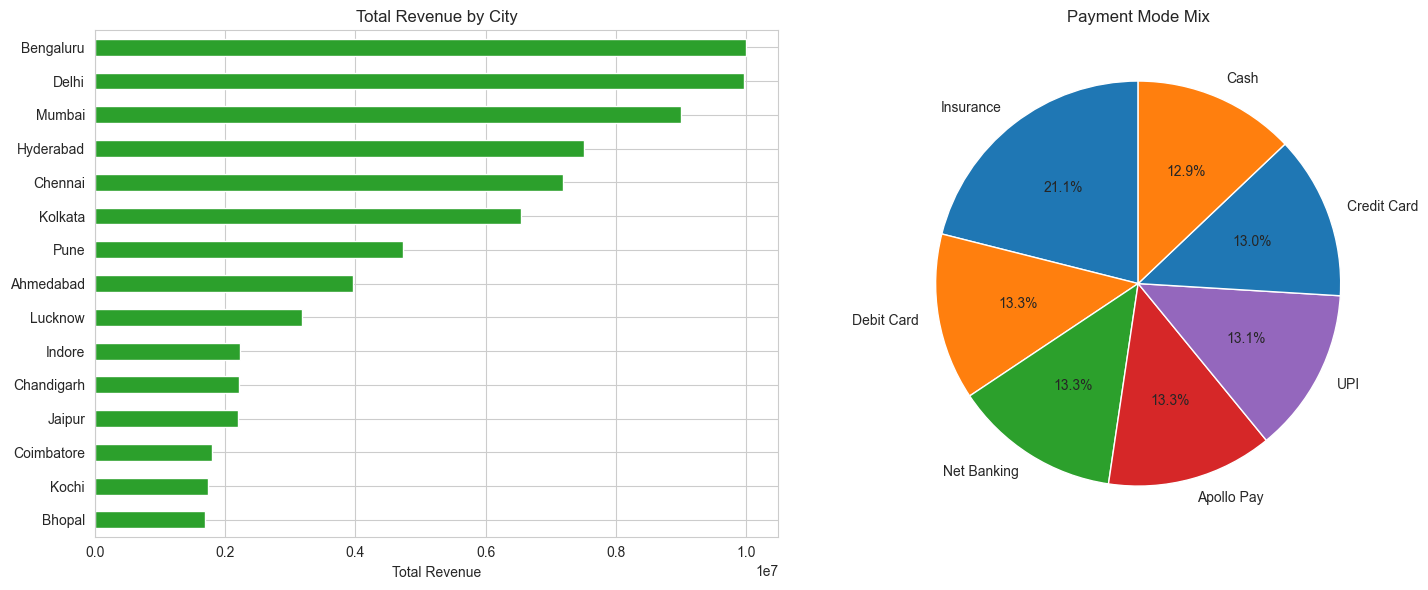

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

rev_city.sort_values().plot(kind="barh", ax=axes[0], color="#2ca02c")
axes[0].set_title("Total Revenue by City")
axes[0].set_xlabel("Total Revenue")
axes[0].set_ylabel("")

axes[1].pie(pay, labels=pay.index, autopct="%1.1f%%", startangle=90,
            colors=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"][:len(pay)])
axes[1].set_title("Payment Mode Mix")

plt.tight_layout()
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• Bengaluru and Delhi earn the most revenue (about 10M each), followed by Mumbai (about 9M). Bhopal, Kochi and Coimbatore earn the least (under 2M).<br>
• Payments are spread almost evenly across 7 modes (about 13% each). Insurance is the largest at 21.1%, so a smooth insurance claim process matters most.
</div>

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Q4.</b> How does insurance coverage affect what patients pay out of pocket?
</div>

## 72. Out-of-Pocket by Insurance Coverage

In [72]:
ins = df_comp.groupby("insurance_coverage")[["actual_fee_charged", "insurance_covered_amount",
                                             "patient_out_of_pocket", "revenue_realized"]].mean()
counts = df_comp["insurance_coverage"].value_counts()
ins["Appointments"] = counts

print("Average amounts per appointment, insured vs uninsured:")
print(ins.round(0))
print()

# Share of the fee that the patient pays themselves
share = df_comp.groupby("insurance_coverage")["patient_out_of_pocket"].sum() / \
        df_comp.groupby("insurance_coverage")["actual_fee_charged"].sum() * 100
print("Patient pays this % of the fee:")
print(share.round(1))

Average amounts per appointment, insured vs uninsured:
                    actual_fee_charged  insurance_covered_amount  \
insurance_coverage                                                 
No                              1563.0                       0.0   
Yes                             1556.0                     697.0   

                    patient_out_of_pocket  revenue_realized  Appointments  
insurance_coverage                                                         
No                                 1563.0            1563.0         37523  
Yes                                 859.0             859.0         17752  

Patient pays this % of the fee:
insurance_coverage
No     100.0
Yes     55.2
dtype: float64


## 73. Out-of-Pocket by Insurance Provider

In [73]:
# "None" = uninsured patients (a valid category, not missing)
prov = df_comp.groupby("insurance_provider")["patient_out_of_pocket"].agg(["mean", "count"])
prov.columns = ["Avg out-of-pocket", "Appointments"]
prov = prov.sort_values("Avg out-of-pocket", ascending=False)

print("Average out-of-pocket by insurance provider:")
print(prov.round(0))

Average out-of-pocket by insurance provider:
                     Avg out-of-pocket  Appointments
insurance_provider                                  
None                            1563.0         37523
New India Assurance              871.0          3598
Star Health                      869.0          3510
Bajaj Allianz                    857.0          3606
HDFC ERGO                        856.0          3497
Niva Bupa                        844.0          3541


## 74. Insurance Charts

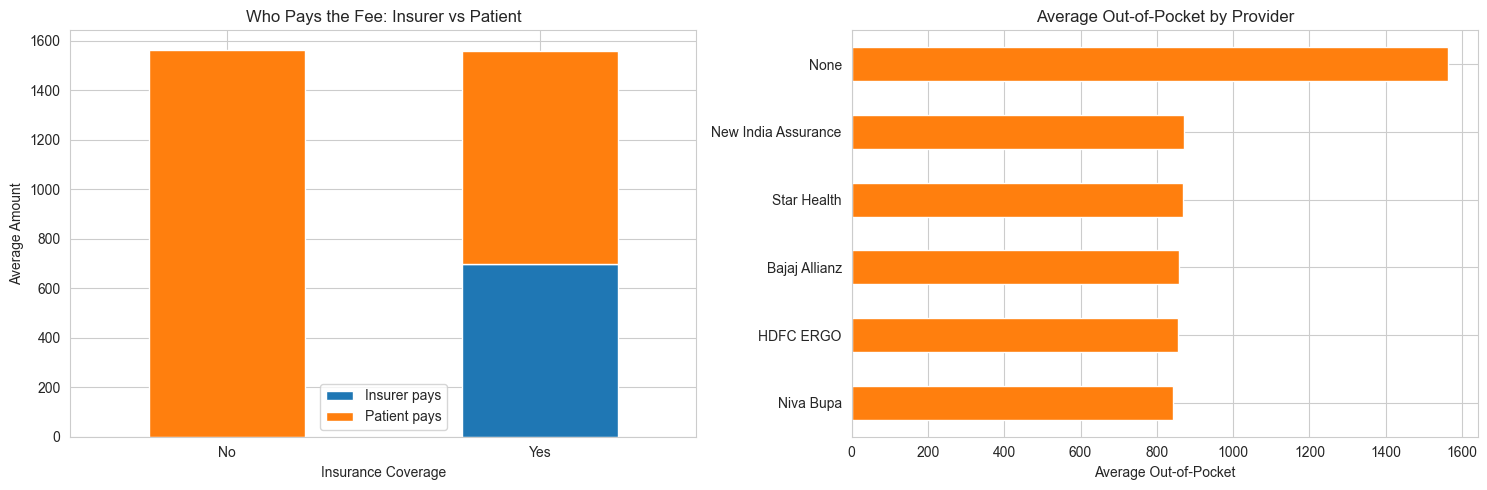

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ins[["insurance_covered_amount", "patient_out_of_pocket"]].plot(
    kind="bar", stacked=True, ax=axes[0], color=["#1f77b4", "#ff7f0e"])
axes[0].set_title("Who Pays the Fee: Insurer vs Patient")
axes[0].set_xlabel("Insurance Coverage")
axes[0].set_ylabel("Average Amount")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(["Insurer pays", "Patient pays"])

prov["Avg out-of-pocket"].sort_values().plot(kind="barh", ax=axes[1], color="#ff7f0e")
axes[1].set_title("Average Out-of-Pocket by Provider")
axes[1].set_xlabel("Average Out-of-Pocket")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• Insurance cuts what patients pay by about 45%: uninsured patients pay about 1,560 per visit, while insured patients pay about 860, because the insurer covers about 690.<br>
• All five insurers leave a similar out-of-pocket amount (about 840 to 870), so no provider is clearly better for patients.
</div>

<hr style="border:3px solid #17becf">

# PART 10: DOCTOR UTILISATION AND SERVICE QUALITY
<a id="part10"></a>

<div style="border-left:6px solid #17becf; padding:8px 14px;">
<b>Q1.</b> Which specialties have the highest and lowest doctor utilisation rates?
</div>

## 75. Utilisation by Specialty

In [75]:
# IMPORTANT: utilisation is one value per doctor per day, so it repeats on every row of that day
# Keep one row per doctor per day before averaging
util_days = df_comp.drop_duplicates(["doctor_id", "appointment_date"])

util = util_days.groupby("specialty")["doctor_utilization_pct"].agg(["mean", "count"])
util.columns = ["Avg utilisation (%)", "Doctor-days"]
util = util.sort_values("Avg utilisation (%)", ascending=False)

print("Average doctor utilisation by specialty:")
print(util.round(2))
print()
print("Highest:", util.index[0], "-", round(util.iloc[0, 0], 2), "%")
print("Lowest :", util.index[-1], "-", round(util.iloc[-1, 0], 2), "%")

Average doctor utilisation by specialty:
                   Avg utilisation (%)  Doctor-days
specialty                                          
Endocrinology                    77.22         1397
Gastroenterology                 77.19         1815
Cardiology                       76.83         3213
Gynaecology                      76.74         2881
Paediatrics                      76.68         4514
Neurology                        76.62         3591
General Physician                76.61        13787
Urology                          76.60         1570
Orthopaedics                     76.46         3860
Dermatology                      76.39         4977
ENT                              76.36         3542
Ophthalmology                    76.23         2178
Pulmonology                      76.22         1791
Psychiatry                       76.15         1840

Highest: Endocrinology - 77.22 %
Lowest : Psychiatry - 76.15 %


## 76. Utilisation Chart

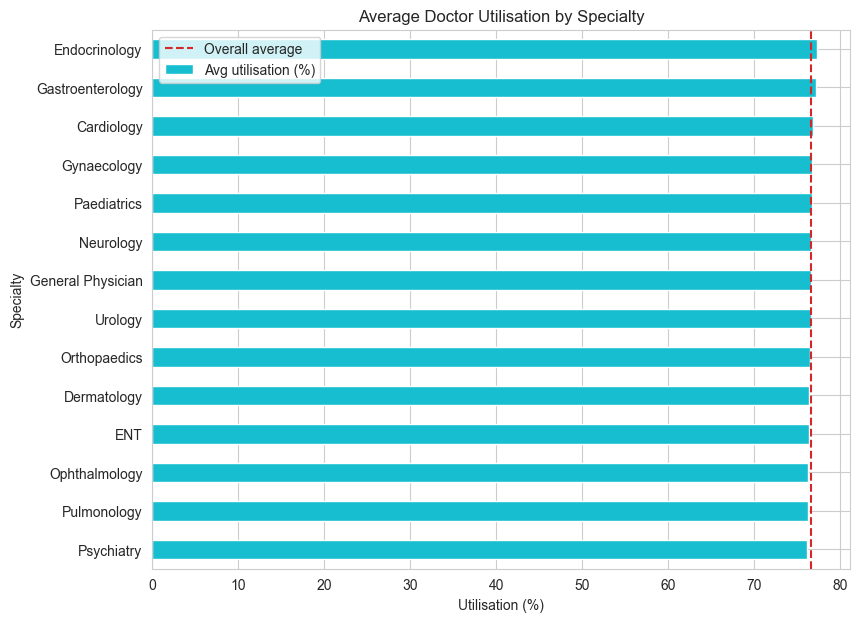

In [76]:
util["Avg utilisation (%)"].sort_values().plot(kind="barh", figsize=(9, 7), color="#17becf")
plt.axvline(util_days["doctor_utilization_pct"].mean(), color="#d62728", linestyle="--", label="Overall average")
plt.title("Average Doctor Utilisation by Specialty")
plt.xlabel("Utilisation (%)")
plt.ylabel("Specialty")
plt.legend()
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• Utilisation is almost the same in every specialty, at about 76-77%. Endocrinology and Gastroenterology are slightly highest, and Psychiatry and Pulmonology slightly lowest.<br>
• The gap between highest and lowest is under 1 point, so specialty does not explain utilisation. About 23% of slots are still empty everywhere, which is where no-shows and cancellations hurt.
</div>

<div style="border-left:6px solid #17becf; padding:8px 14px;">
<b>Q2.</b> How long are patients waiting and does it vary by specialty or time of day?
</div>

## 77. Overall Waiting Time

In [77]:
print("Average wait (minutes):", round(df_comp["wait_time_minutes"].mean(), 1))
print("Median wait (minutes) :", df_comp["wait_time_minutes"].median())
print("Longest wait (minutes):", df_comp["wait_time_minutes"].max())

Average wait (minutes): 11.5
Median wait (minutes) : 8.0
Longest wait (minutes): 90.0


## 78. Waiting Time by Specialty

In [78]:
wait_spec = df_comp.groupby("specialty")["wait_time_minutes"].mean().sort_values(ascending=False)

print("Average wait (minutes) by specialty:")
print(wait_spec.round(1))

Average wait (minutes) by specialty:
specialty
Ophthalmology        12.0
Urology              11.9
Dermatology          11.8
Orthopaedics         11.7
Neurology            11.6
Gynaecology          11.6
Cardiology           11.6
General Physician    11.5
Endocrinology        11.5
Gastroenterology     11.4
Pulmonology          11.4
Psychiatry           11.3
ENT                  11.3
Paediatrics          11.2
Name: wait_time_minutes, dtype: float64


## 79. Waiting Time by Time of Day

In [79]:
wait_tod = df_comp.groupby("time_of_day")["wait_time_minutes"].mean()
wait_tod = wait_tod.reindex(["Morning", "Afternoon", "Evening"])

print("Average wait (minutes) by time of day:")
print(wait_tod.round(1))

Average wait (minutes) by time of day:
time_of_day
Morning      11.5
Afternoon    11.6
Evening      11.6
Name: wait_time_minutes, dtype: float64


## 80. Waiting Time Charts

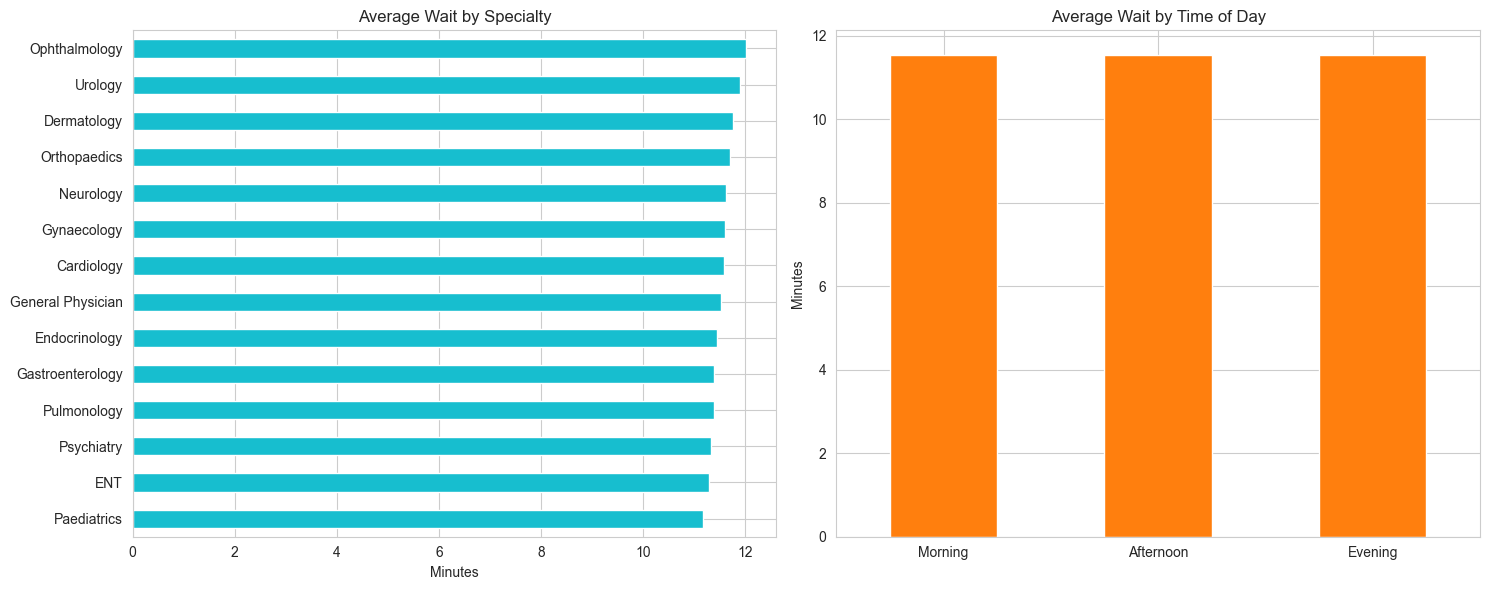

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

wait_spec.sort_values().plot(kind="barh", ax=axes[0], color="#17becf")
axes[0].set_title("Average Wait by Specialty")
axes[0].set_xlabel("Minutes")
axes[0].set_ylabel("")

wait_tod.plot(kind="bar", ax=axes[1], color="#ff7f0e")
axes[1].set_title("Average Wait by Time of Day")
axes[1].set_xlabel("")
axes[1].set_ylabel("Minutes")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• Patients wait about 11.5 minutes on average. Specialties range only from about 11.2 minutes (Paediatrics) to about 12 minutes (Ophthalmology).<br>
• Wait is the same in the morning, afternoon and evening, so neither specialty nor time of day drives waiting. Wait time is already short and is not a problem area.
</div>

<div style="border-left:6px solid #17becf; padding:8px 14px;">
<b>Q3.</b> Is there a relationship between consultation duration and patient satisfaction?
</div>

## 81. Correlation

In [81]:
corr_ds = df_comp["consultation_duration_min"].corr(df_comp["patient_satisfaction_score"])
print("Correlation (duration vs satisfaction):", round(corr_ds, 3))

Correlation (duration vs satisfaction): -0.004


## 82. Average Duration for Each Satisfaction Score

In [82]:
# Satisfaction is a score from 1 to 5, so a table by score is easier to read than raw points
by_score = df_comp.groupby("patient_satisfaction_score")["consultation_duration_min"].agg(["mean", "count"])
by_score.columns = ["Avg duration (min)", "Appointments"]

print("Average consultation duration by satisfaction score:")
print(by_score.round(1))

Average consultation duration by satisfaction score:
                            Avg duration (min)  Appointments
patient_satisfaction_score                                  
1.0                                       21.0             1
1.2                                       33.0             2
1.3                                       31.0             1
1.4                                        8.0             2
1.5                                       21.2             4
1.6                                       18.3             7
1.7                                       14.9             9
1.8                                       18.0            11
1.9                                       17.8            19
2.0                                       17.4            35
2.1                                       17.2            46
2.2                                       19.1            96
2.3                                       18.2           107
2.4                             

## 83. Duration vs Satisfaction Charts

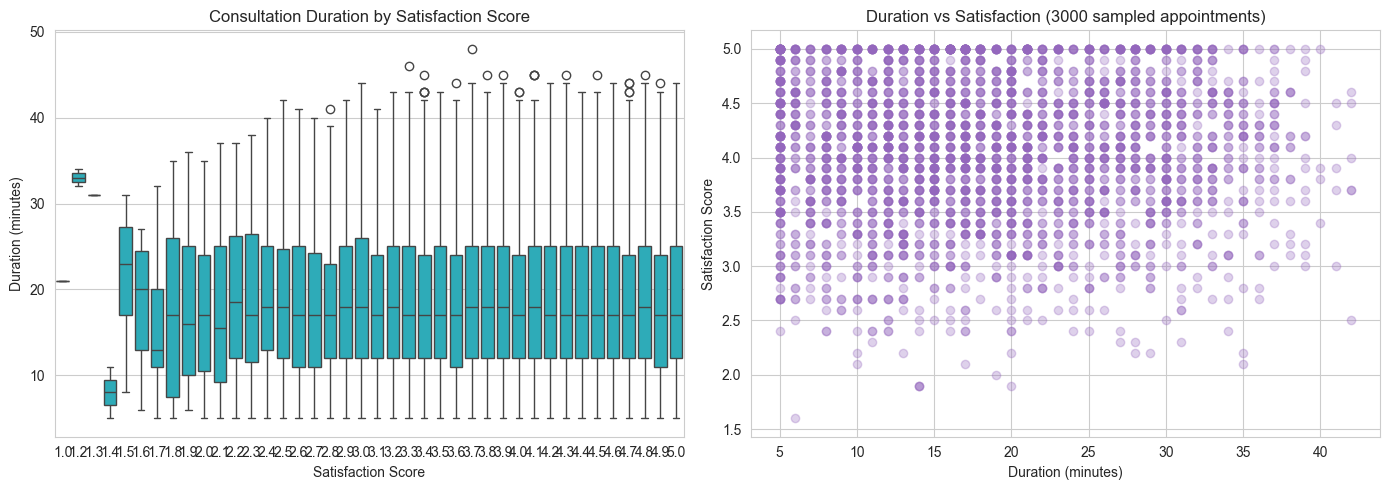

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_comp, x="patient_satisfaction_score", y="consultation_duration_min",
            color="#17becf", ax=axes[0])
axes[0].set_title("Consultation Duration by Satisfaction Score")
axes[0].set_xlabel("Satisfaction Score")
axes[0].set_ylabel("Duration (minutes)")

# A sample of 3000 points keeps the scatter readable
sample = df_comp.sample(3000, random_state=1)
axes[1].scatter(sample["consultation_duration_min"], sample["patient_satisfaction_score"],
                alpha=0.3, color="#9467bd")
axes[1].set_title("Duration vs Satisfaction (3000 sampled appointments)")
axes[1].set_xlabel("Duration (minutes)")
axes[1].set_ylabel("Satisfaction Score")

plt.tight_layout()
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• There is little or no relationship between consultation length and satisfaction: scores are mostly between 3 and 5 whether the visit lasts 10 or 40 minutes.<br>
• Satisfaction does not rise with longer visits, so Apollo should not stretch consultations to raise scores and should look at other drivers instead.
</div>

<div style="border-left:6px solid #17becf; padding:8px 14px;">
<b>Q4.</b> How does doctor experience relate to the fee charged (join with doctors dim)?
</div>

## 84. Join with the Doctors Table

In [84]:
# IMPORTANT: both tables have consultation_fee, so rename the doctors one before joining
doc_small = doctors[["doctor_id", "experience_years", "rating", "consultation_fee"]]
doc_small = doc_small.rename(columns={"consultation_fee": "doctor_fee"})

df_doc = df_comp.merge(doc_small, on="doctor_id", how="left")

print("Rows after join:", len(df_doc), "(should equal", len(df_comp), ")")
print("Rows with no matching doctor:", df_doc["experience_years"].isna().sum())

Rows after join: 55275 (should equal 55275 )
Rows with no matching doctor: 0


## 85. Experience vs Fee

In [85]:
# Experience groups in years
doctors["exp_group"] = pd.cut(doctors["experience_years"],
                              bins=[0, 5, 10, 15, 20, 35],
                              labels=["0-5", "6-10", "11-15", "16-20", "21+"])

corr_ef = doctors["experience_years"].corr(doctors["consultation_fee"])
print("Correlation (experience vs listed fee):", round(corr_ef, 3))
print()
print("Average listed fee by experience group:")
print(doctors.groupby("exp_group", observed=True)["consultation_fee"].agg(["mean", "count"]).round(0))
print()
print("Average actual fee charged by experience group (Completed appointments):")
df_doc["exp_group"] = pd.cut(df_doc["experience_years"], bins=[0, 5, 10, 15, 20, 35],
                             labels=["0-5", "6-10", "11-15", "16-20", "21+"])
print(df_doc.groupby("exp_group", observed=True)["actual_fee_charged"].mean().round(0))

Correlation (experience vs listed fee): 0.278

Average listed fee by experience group:
             mean  count
exp_group               
0-5        1320.0     51
6-10       1445.0     60
11-15      1515.0     46
16-20      1530.0     60
21+        1850.0    103

Average actual fee charged by experience group (Completed appointments):
exp_group
0-5      1304.0
6-10     1432.0
11-15    1476.0
16-20    1521.0
21+      1823.0
Name: actual_fee_charged, dtype: float64


## 86. Experience vs Fee Charts

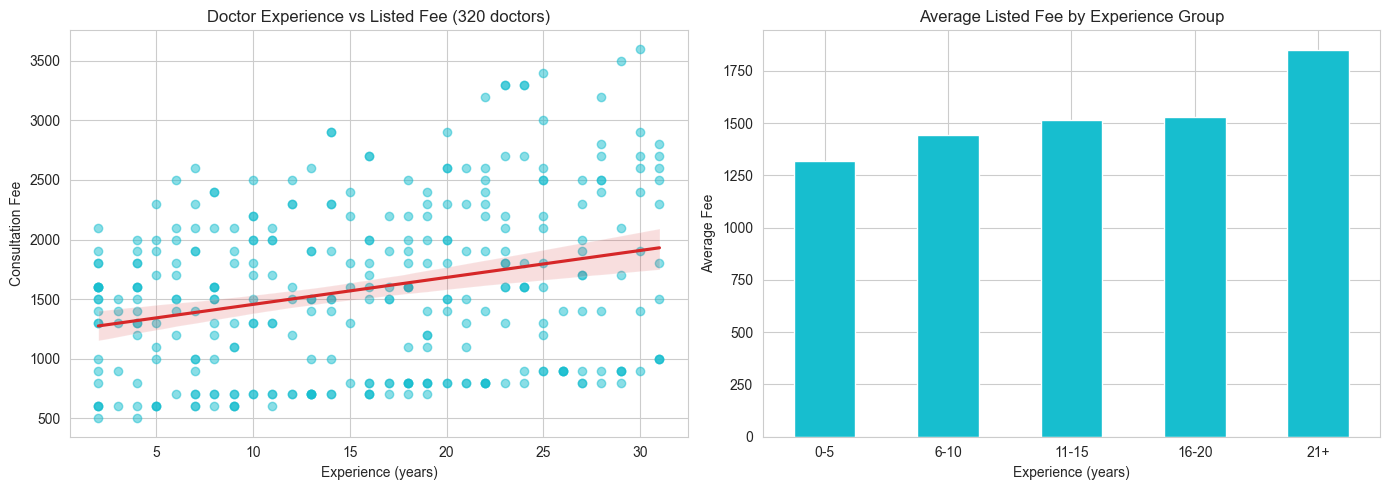

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(data=doctors, x="experience_years", y="consultation_fee",
            scatter_kws={"alpha": 0.5, "color": "#17becf"}, line_kws={"color": "#d62728"}, ax=axes[0])
axes[0].set_title("Doctor Experience vs Listed Fee (320 doctors)")
axes[0].set_xlabel("Experience (years)")
axes[0].set_ylabel("Consultation Fee")

doctors.groupby("exp_group", observed=True)["consultation_fee"].mean().plot(
    kind="bar", ax=axes[1], color="#17becf")
axes[1].set_title("Average Listed Fee by Experience Group")
axes[1].set_xlabel("Experience (years)")
axes[1].set_ylabel("Average Fee")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

<div style="border-left:6px solid #2ca02c; padding:8px 14px;">
<b>Insight:</b><br>
• Fees rise with experience: the average listed fee goes from about 1,300 for doctors with 0-5 years to about 1,850 for those with 21+ years, and the trend line slopes upward.<br>
• The link is only moderate, because fees at any experience level range from about 600 to 3,500. Specialty and city likely affect fees too, so experience is only part of the story.
</div>

<hr style="border:3px solid #1f77b4">

# FINAL SUMMARY AND RECOMMENDATIONS

## Key findings
- Volume is flat at about 25,000 appointments a year, with a peak in Q4 and a dip in June to August.
- The overall no-show rate is 15.94%, about 1 in 6 booked appointments.
- No-shows cost an estimated 15.7M to 19.7M, about 21% of the 73.9M revenue earned.

## Top drivers of no-shows
- First-time patients: 66.8% no-show, against 8.6% for repeat patients.
- No reminders: about 30% no-show, falling to about 11% with three reminders.
- Prior no-shows: about 33% for 3 or more, against about 15% for none.
- Lead time: about 20% for bookings 15-30 days ahead, against about 13% same-day.

## Recommendations
1. Send at least one reminder to every booking, and the full bundle to first-time and long-lead bookings.
2. Call first-time patients and patients with 2 or more prior no-shows to confirm.
3. Add extra reminders for Home Visit and Video Consult bookings.
4. Plan doctor capacity around the Q4 and Q1 peak.

## Limits
- Results show association, not proof of cause.
- Lost revenue is an estimate, because revenue is 0 for no-shows.